# Task 1: Analyze the correlation between job title keywords and offered salaries

In [102]:
# Dataset loading and exploration

In [103]:
# Import Libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

# Statistical analysis
from scipy import stats

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

sns.set_style("whitegrid")

In [104]:
# Load the data 
df = pd.read_csv("D:\\DIGICROME\\project8\\all_upwork_jobs.csv")

In [105]:
df.shape

(244828, 8)

In [106]:
df.head(5)

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and Roofing installation companies.,https://www.upwork.com/jobs/Experienced-Media-Buyer-For-Solar-Pannel-and-Roofing-installation-co...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Developer_%7E011604a02b364315a8?source=rss,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7E0166a7749b263ff2e0?source=rss,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Specialized-Marketing_%7E016285f94066dffb31?source=rss,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E015c34d1bcadde8702?source=rss,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [107]:
df.columns

Index(['title', 'link', 'published_date', 'is_hourly', 'hourly_low',
       'hourly_high', 'budget', 'country'],
      dtype='object')

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


In [109]:
df.describe(include='all')

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
count,244827,244827,244828,244828,102422.000000,98775.000000,103891.000000,239751
unique,205470,244827,233640,2,NaN,NaN,NaN,212
top,Social Media Manager,https://www.upwork.com/jobs/Experienced-Media-Buyer-For-Solar-Pannel-and-Roofing-installation-co...,2024-02-24 13:04:28+00:00,True,NaN,NaN,NaN,United States
freq,419,1,6,140937,NaN,NaN,NaN,99834
mean,NaN,NaN,NaN,NaN,17.339644,41.970610,911.473564,NaN
std,NaN,NaN,NaN,NaN,18.140065,47.850892,15729.738834,NaN
min,NaN,NaN,NaN,NaN,3.000000,3.000000,5.000000,NaN
25%,NaN,NaN,NaN,NaN,8.000000,20.000000,25.000000,NaN
50%,NaN,NaN,NaN,NaN,15.000000,30.000000,100.000000,NaN
75%,NaN,NaN,NaN,NaN,20.000000,50.000000,300.000000,NaN


In [110]:
# Check Missing Values 

missing_values = pd.DataFrame({
    'Missing Values':df.isnull().sum(),
    'Missing Percentage':(df.isnull().sum()/len(df) * 100)
})

missing_values

,Missing Values,Missing Percentage
title,1,0.000408
link,1,0.000408
published_date,0,0.000000
is_hourly,0,0.000000
hourly_low,142406,58.165733
hourly_high,146053,59.655350
budget,140937,57.565720
country,5077,2.073701


In [111]:
# Check Duplicated records 
print("Duplicated Records:",df.duplicated().sum())

Duplicated Records: 0


In [112]:
# Data Cleaning and Preprocessing

In [113]:
# Create a copy of original dataset 

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (244828, 8)
Working Dataset Shape: (244828, 8)


In [114]:
# remove missing data 

df_clean = df_clean.dropna(subset=['title'])

In [115]:
df_clean.shape

(244827, 8)

In [116]:
df_clean['title'] = df_clean['title'].str.lower()

df_clean['title'] = df_clean['title'].str.strip()

In [117]:
df_clean['title'].head(10)

0                experienced media buyer for solar pannel and roofing installation companies.
1                                                                        full stack developer
2                                                                             smma bubble app
3                                                      talent hunter specialized in marketing
4                                                                               data engineer
5                                                        seo for portuguese psychologist site
6                                                            want to fix the wordpress plugin
7                           need portuguese writers who can understand and write portuguese..
8    looker studio dashboard for leadgen and e-commerce with tool &quot;reporting ninja&quot;
9                          php/html/css wordpress developer needed for website transformation
Name: title, dtype: object

In [118]:
# Convert publication date into datetime

df_clean['published_date'] = pd.to_datetime(
    df_clean['published_date'],
    errors='coerce',
    utc=True
)

print(df_clean['published_date'].dtype)


datetime64[ns, UTC]


In [119]:
# Separate hourly and fixed-price jobs

# hourly job posting 
hourly_df = df_clean[df_clean['is_hourly']==True].copy()

# Fixed-price job postings
fixed_df = df_clean[df_clean['is_hourly'] == False].copy()

print("Hourly Jobs:", hourly_df.shape)
print("Fixed Price Jobs:", fixed_df.shape)

Hourly Jobs: (140936, 8)
Fixed Price Jobs: (103891, 8)


In [120]:
# Check cleaning results

print("Missing Titles:", df_clean['title'].isnull().sum())

print("Duplicate Records:", df_clean.duplicated().sum())

print("Missing Dates:", df_clean['published_date'].isnull().sum())

print("\nHourly Dataset Missing Values:")
print(hourly_df[['hourly_low', 'hourly_high']].isnull().sum())

print("\nFixed Price Dataset Missing Values:")
print(fixed_df['budget'].isnull().sum())

Missing Titles: 0
Duplicate Records: 0
Missing Dates: 0

Hourly Dataset Missing Values:
hourly_low     38514
hourly_high    42161
dtype: int64

Fixed Price Dataset Missing Values:
0


In [121]:
# Salary calculation and distribution analysis

# Calculate hourly salary midpoint

hourly_df['hourly_midpoint'] = (
    hourly_df['hourly_low'] + hourly_df['hourly_high']
) / 2

# Display selected columns
display(
    hourly_df[
        ['title', 'hourly_low', 'hourly_high', 'hourly_midpoint']
    ].head(10)
)

,title,hourly_low,hourly_high,hourly_midpoint
2,smma bubble app,10.0,30.0,20.0
3,talent hunter specialized in marketing,NaN,NaN,NaN
5,seo for portuguese psychologist site,NaN,NaN,NaN
7,need portuguese writers who can understand and write portuguese..,7.0,22.0,14.5
8,looker studio dashboard for leadgen and e-commerce with tool &quot;reporting ninja&quot;,NaN,NaN,NaN
12,affiliate marketing,NaN,NaN,NaN
13,urgent: fix emails not working on discourse installation,40.0,75.0,57.5
15,web3 full-stack developer,30.0,50.0,40.0
18,"website design, ui/ux design",12.0,30.0,21.0
19,customer service,4.0,8.0,6.0


In [122]:
# Check missing salary values

print("Total Hourly Jobs:", len(hourly_df))

print(
    "Missing Salary Midpoints:",
    hourly_df['hourly_midpoint'].isnull().sum()
)

print(
    "Available Salary Midpoints:",
    hourly_df['hourly_midpoint'].notnull().sum()
)

Total Hourly Jobs: 140936
Missing Salary Midpoints: 42161
Available Salary Midpoints: 98775


In [123]:
# Keep records with available hourly midpoint
salary_df = hourly_df.dropna(
    subset=['hourly_midpoint']
).copy()

print("Salary Analysis Dataset:", salary_df.shape)

Salary Analysis Dataset: (98775, 9)


In [124]:
salary_stats = salary_df['hourly_midpoint'].describe()

display(salary_stats)

count    98775.000000
mean        29.709263
std         30.488625
min          3.000000
25%         14.000000
50%         22.500000
75%         35.000000
max        998.500000
Name: hourly_midpoint, dtype: float64

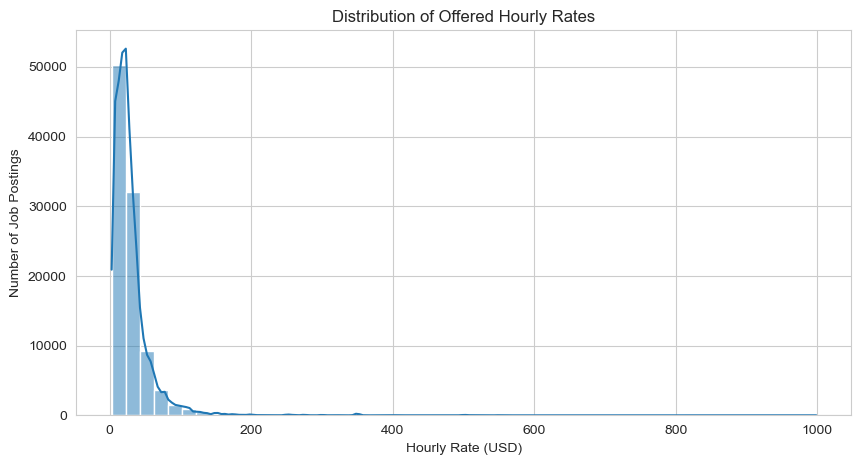

In [125]:
# Visualize hourly salary distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=salary_df,
    x='hourly_midpoint',
    bins=50,
    kde=True
)

plt.title('Distribution of Offered Hourly Rates')
plt.xlabel('Hourly Rate (USD)')
plt.ylabel('Number of Job Postings')

plt.show()

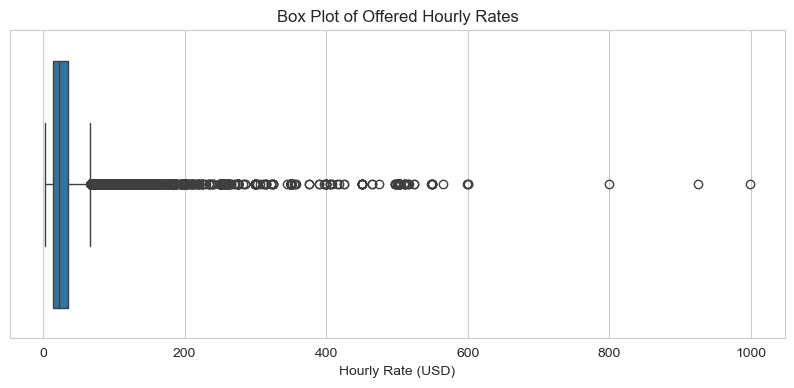

In [126]:
# Create a box plot to identify outliers

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=salary_df['hourly_midpoint']
)

plt.title('Box Plot of Offered Hourly Rates')
plt.xlabel('Hourly Rate (USD)')

plt.show()

In [127]:
# Check the highest and lowest hourly rates

print("Lowest 10 Hourly Rates:")

display(
    salary_df.nsmallest(
        10, 'hourly_midpoint'
    )[['title', 'hourly_low', 'hourly_high', 'hourly_midpoint']]
)

print("Highest 10 Hourly Rates:")

display(
    salary_df.nlargest(
        10, 'hourly_midpoint'
    )[['title', 'hourly_low', 'hourly_high', 'hourly_midpoint']]
)


Lowest 10 Hourly Rates:


,title,hourly_low,hourly_high,hourly_midpoint
7881,software developer (backend focus) for e-commerce stock management system,3.0,3.0,3.0
10261,social media marketing for ai app,3.0,3.0,3.0
10659,instagram dm appointment setter,3.0,3.0,3.0
15866,philipino va required to source 100 ozempic clnic leads per day (with room to grow),3.0,3.0,3.0
20950,digital assistant - shopify - google sheets - internal email - general data entry,3.0,3.0,3.0
34089,openai sora consultant and prompt engineer,3.0,3.0,3.0
37928,email marketing pro,3.0,3.0,3.0
41101,"image download, and data entry",3.0,3.0,3.0
44882,chief of staff // executive assistant | to be the founder's right-hand | part-time to full-time |,3.0,3.0,3.0
48135,reviewers for our businesses,3.0,3.0,3.0


Highest 10 Hourly Rates:


,title,hourly_low,hourly_high,hourly_midpoint
226364,data engineering proxy help,998.0,999.0,998.5
205943,sales marketing executive,900.0,950.0,925.0
144728,freelancing - support work / attractive pay per hour\ntime : 4hrs daily between 7pm to 4 am,600.0,999.0,799.5
216753,product packaging design for diabetic care product,500.0,700.0,600.0
240878,blockchain solidity engineer,400.0,800.0,600.0
241364,lawyer that we can partner up with.,200.0,999.0,599.5
47841,south african local language writer and speaker,210.0,920.0,565.0
43623,sales call closer for short form agency,200.0,900.0,550.0
59861,i want a task html &amp;css,500.0,600.0,550.0
236370,company legal representative to communicate with the payment service,400.0,700.0,550.0


In [128]:
# Job title keyword extraction

# Create a separate keyword analysis dataset

keyword_df = salary_df[
    ['title', 'hourly_low', 'hourly_high', 'hourly_midpoint']
].copy()

# Remove any remaining missing titles
keyword_df = keyword_df.dropna(subset=['title'])

# Reset index
keyword_df.reset_index(drop=True, inplace=True)

# Display sample records
display(keyword_df.head(10))

print("Total Records:", len(keyword_df))

,title,hourly_low,hourly_high,hourly_midpoint
0,smma bubble app,10.0,30.0,20.0
1,need portuguese writers who can understand and write portuguese..,7.0,22.0,14.5
2,urgent: fix emails not working on discourse installation,40.0,75.0,57.5
3,web3 full-stack developer,30.0,50.0,40.0
4,"website design, ui/ux design",12.0,30.0,21.0
5,customer service,4.0,8.0,6.0
6,report analysis,15.0,30.0,22.5
7,linkedin ads coach,15.0,50.0,32.5
8,capcut genius,6.0,15.0,10.5
9,social media pro to write and post to instagram,5.0,15.0,10.0


Total Records: 98775


In [129]:
# Extract individual words from job titles

import re
from collections import Counter

#Extract individual words from job titles 
all_words = []

for title in keyword_df['title']:
    words = re.findall(r'\b[a-zA-Z]+\b', title.lower())
    all_words.extend(words)

# Count keyword frequency
word_counts = Counter(all_words)

# Convert to DataFrame
word_frequency = pd.DataFrame(
    word_counts.items(),
    columns=['keyword', 'frequency']
)

# Sort by frequency
word_frequency = word_frequency.sort_values(
    by='frequency',
    ascending=False
).reset_index(drop=True)

# Display top 20 keywords
display(word_frequency.head(20))

,keyword,frequency
0,for,28008
1,and,15339
2,to,9710
3,a,8726
4,developer,7597
5,needed,7187
6,expert,7075
7,website,5883
8,designer,5647
9,with,5526


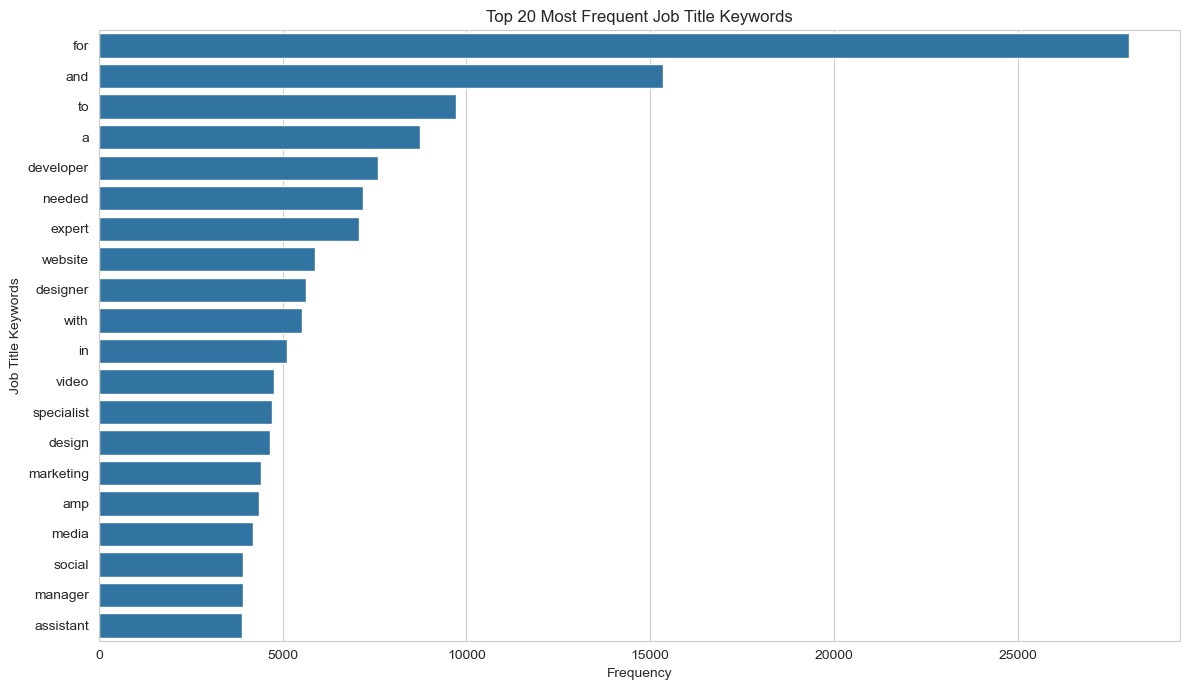

In [130]:
# Visualize the top 20 keywords
plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_frequency.head(20),
    x='frequency',
    y='keyword'
)

plt.title('Top 20 Most Frequent Job Title Keywords')
plt.xlabel('Frequency')
plt.ylabel('Job Title Keywords')

plt.tight_layout()
plt.show()

In [131]:
# Important multiword keywords
important_phrases = [
    'machine learning',
    'data science',
    'full stack',
    'digital marketing',
    'artificial intelligence',
    'social media',
    'project management',
    'deep learning',
    'web development',
    'graphic design'
]

phrase_counts = {}

for phrase in important_phrases:
    phrase_counts[phrase] = keyword_df['title'].str.contains(
        rf'\b{re.escape(phrase)}\b',
        case=False,
        regex=True,
        na=False
    ).sum()

phrase_frequency = pd.DataFrame(
    phrase_counts.items(),
    columns=['keyword', 'frequency']
).sort_values(
    by='frequency',
    ascending=False
)

display(phrase_frequency)

,keyword,frequency
5,social media,3654
2,full stack,903
3,digital marketing,656
9,graphic design,403
0,machine learning,137
6,project management,122
8,web development,105
1,data science,33
4,artificial intelligence,31
7,deep learning,15


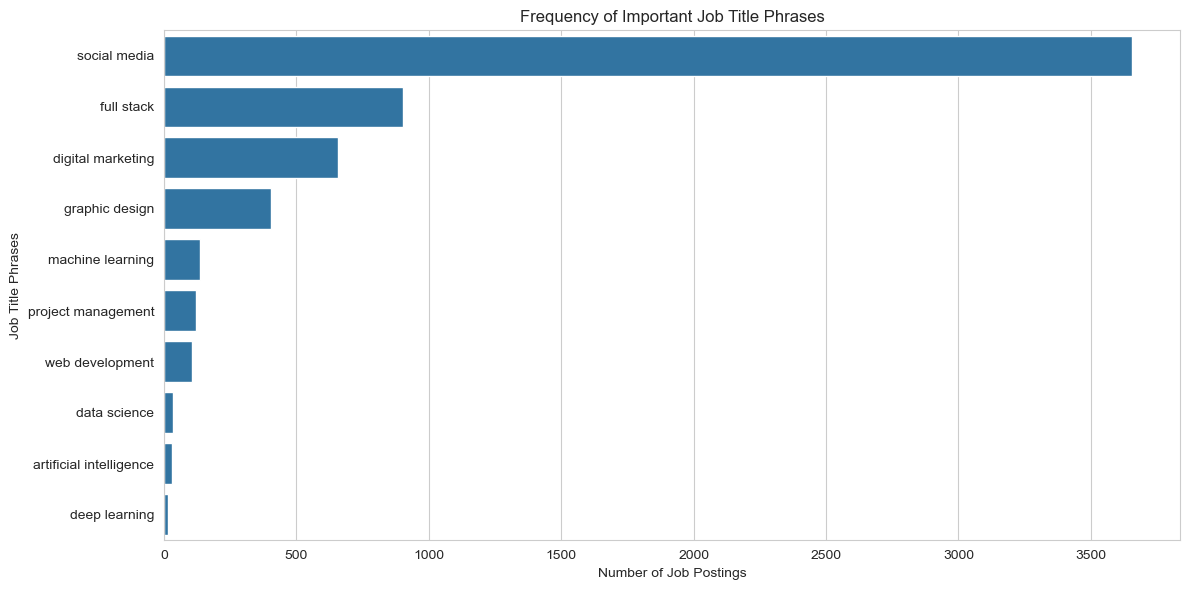

In [132]:
# Create a combined keyword frequency visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=phrase_frequency,
    x='frequency',
    y='keyword'
)

plt.title('Frequency of Important Job Title Phrases')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Title Phrases')

plt.tight_layout()
plt.show()

In [133]:
# Remove stopwords and clean keywords

import html
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [134]:
# Decode HTML entities and normalize text
keyword_df['clean_title'] = (
    keyword_df['title']
    .apply(html.unescape)
    .str.lower()
    .str.strip()
)

# Display examples
display(
    keyword_df[['title', 'clean_title']].head(10)
)

,title,clean_title
0,smma bubble app,smma bubble app
1,need portuguese writers who can understand and write portuguese..,need portuguese writers who can understand and write portuguese..
2,urgent: fix emails not working on discourse installation,urgent: fix emails not working on discourse installation
3,web3 full-stack developer,web3 full-stack developer
4,"website design, ui/ux design","website design, ui/ux design"
5,customer service,customer service
6,report analysis,report analysis
7,linkedin ads coach,linkedin ads coach
8,capcut genius,capcut genius
9,social media pro to write and post to instagram,social media pro to write and post to instagram


In [135]:
# Remove stopwords

# Standard English stopwords
stop_words = set(ENGLISH_STOP_WORDS)

# Additional job-posting filler words
custom_stopwords = {
    'needed',
    'need',
    'looking',
    'want',
    'required',
    'please',
    'amp'
}

stop_words.update(custom_stopwords)

# Extract meaningful words
def extract_keywords(title):

    words = re.findall(r'\b[a-zA-Z]+\b', title.lower())

    meaningful_words = [
        word for word in words
        if word not in stop_words
    ]

    return meaningful_words


# Apply keyword extraction
keyword_df['keywords'] = keyword_df['clean_title'].apply(
    extract_keywords
)

# Display results
display(
    keyword_df[['clean_title', 'keywords']].head(10)
)

,clean_title,keywords
0,smma bubble app,"[smma, bubble, app]"
1,need portuguese writers who can understand and write portuguese..,"[portuguese, writers, understand, write, portuguese]"
2,urgent: fix emails not working on discourse installation,"[urgent, fix, emails, working, discourse, installation]"
3,web3 full-stack developer,"[stack, developer]"
4,"website design, ui/ux design","[website, design, ui, ux, design]"
5,customer service,"[customer, service]"
6,report analysis,"[report, analysis]"
7,linkedin ads coach,"[linkedin, ads, coach]"
8,capcut genius,"[capcut, genius]"
9,social media pro to write and post to instagram,"[social, media, pro, write, post, instagram]"


In [136]:
# Calculate cleaned keyword frequency

# Combine all extracted keywords
cleaned_words = [
    word
    for words in keyword_df['keywords']
    for word in words
]

# Count keyword frequency
cleaned_word_counts = Counter(cleaned_words)

# Create DataFrame
cleaned_word_frequency = pd.DataFrame(
    cleaned_word_counts.items(),
    columns=['keyword', 'frequency']
)

# Sort by frequency
cleaned_word_frequency = cleaned_word_frequency.sort_values(
    by='frequency',
    ascending=False
).reset_index(drop=True)

# Display top 20
display(cleaned_word_frequency.head(20))

,keyword,frequency
0,developer,7597
1,expert,7075
2,website,5883
3,designer,5647
4,video,4759
5,specialist,4717
6,design,4664
7,marketing,4404
8,media,4194
9,social,3917


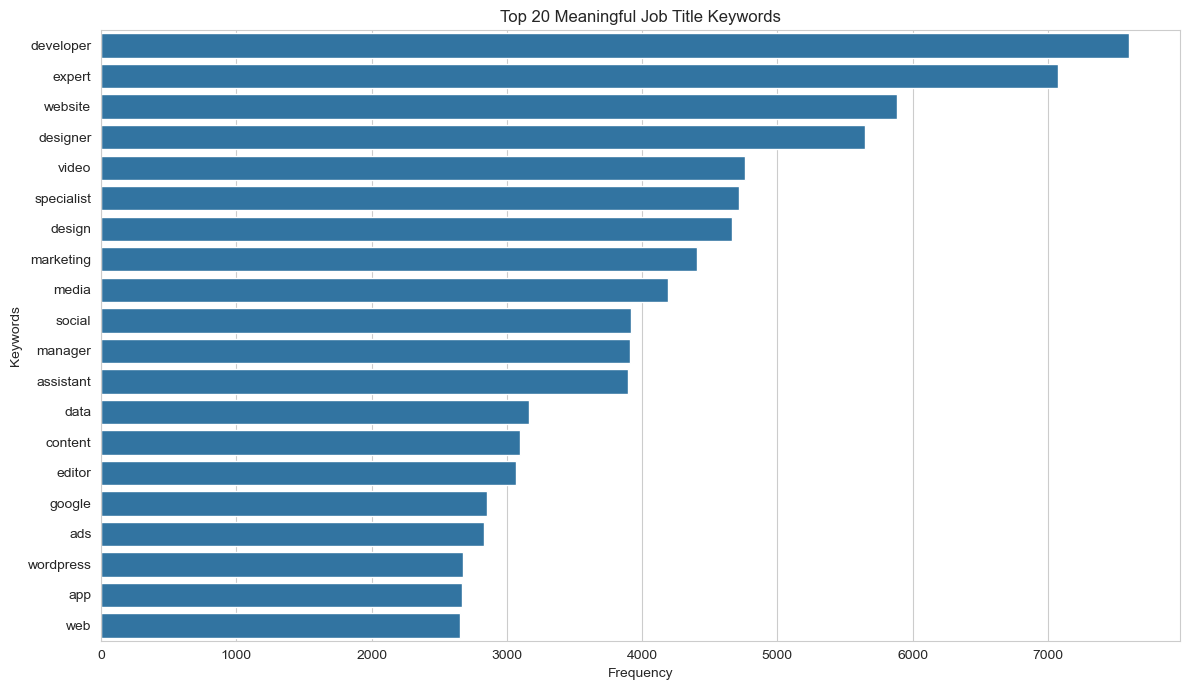

In [137]:
# Visualize cleaned keywords

plt.figure(figsize=(12, 7))

sns.barplot(
    data=cleaned_word_frequency.head(20),
    x='frequency',
    y='keyword'
)

plt.title('Top 20 Meaningful Job Title Keywords')
plt.xlabel('Frequency')
plt.ylabel('Keywords')

plt.tight_layout()
plt.show()

In [138]:
# Normalize separators in job titles
keyword_df['clean_title'] = (
    keyword_df['title']
    .apply(html.unescape)
    .str.lower()
    .str.replace(r'[-_/]+', ' ', regex=True)
    .str.strip()
)

# Re-extract keywords
keyword_df['keywords'] = keyword_df['clean_title'].apply(
    extract_keywords
)

display(
    keyword_df[['title', 'clean_title', 'keywords']].head(10)
)

,title,clean_title,keywords
0,smma bubble app,smma bubble app,"[smma, bubble, app]"
1,need portuguese writers who can understand and write portuguese..,need portuguese writers who can understand and write portuguese..,"[portuguese, writers, understand, write, portuguese]"
2,urgent: fix emails not working on discourse installation,urgent: fix emails not working on discourse installation,"[urgent, fix, emails, working, discourse, installation]"
3,web3 full-stack developer,web3 full stack developer,"[stack, developer]"
4,"website design, ui/ux design","website design, ui ux design","[website, design, ui, ux, design]"
5,customer service,customer service,"[customer, service]"
6,report analysis,report analysis,"[report, analysis]"
7,linkedin ads coach,linkedin ads coach,"[linkedin, ads, coach]"
8,capcut genius,capcut genius,"[capcut, genius]"
9,social media pro to write and post to instagram,social media pro to write and post to instagram,"[social, media, pro, write, post, instagram]"


In [139]:
# Keyword-wise salary analysis

# Select top 30 frequent keywords
top_keywords = (
    cleaned_word_frequency
    .head(30)['keyword']
    .tolist()
)

# Add important technical and job-role keywords
additional_keywords = [
    'python',
    'sql',
    'power bi',
    'machine learning',
    'data science',
    'artificial intelligence',
    'deep learning',
    'data analyst',
    'data scientist',
    'project manager',
    'project management',
    'software engineer',
    'full stack',
    'senior',
    'junior',
    'lead',
    'principal',
    'consultant',
    'engineer',
    'developer',
    'manager'
]

# Combine and remove duplicates
selected_keywords = list(
    dict.fromkeys(top_keywords + additional_keywords)
)

print("Total Selected Keywords:", len(selected_keywords))
print(selected_keywords)

Total Selected Keywords: 49
['developer', 'expert', 'website', 'designer', 'video', 'specialist', 'design', 'marketing', 'media', 'social', 'manager', 'assistant', 'data', 'content', 'editor', 'google', 'ads', 'wordpress', 'app', 'web', 'business', 'development', 'graphic', 'youtube', 'project', 'virtual', 'shopify', 'help', 'create', 'sales', 'python', 'sql', 'power bi', 'machine learning', 'data science', 'artificial intelligence', 'deep learning', 'data analyst', 'data scientist', 'project manager', 'project management', 'software engineer', 'full stack', 'senior', 'junior', 'lead', 'principal', 'consultant', 'engineer']


In [140]:
# Calculate keyword-wise salary statistics

keyword_salary_results = []

for keyword in selected_keywords:

    pattern = rf'(?<!\w){re.escape(keyword)}(?!\w)'

    # Select jobs containing the keyword
    matched_jobs = keyword_df[
        keyword_df['clean_title'].str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    ]

    # Calculate salary statistics
    keyword_salary_results.append({
        'keyword': keyword,
        'job_count': len(matched_jobs),
        'mean_salary': matched_jobs['hourly_midpoint'].mean(),
        'median_salary': matched_jobs['hourly_midpoint'].median(),
        'min_salary': matched_jobs['hourly_midpoint'].min(),
        'max_salary': matched_jobs['hourly_midpoint'].max()
    })

# Create DataFrame
keyword_salary_df = pd.DataFrame(keyword_salary_results)

# Sort by average salary
keyword_salary_df = keyword_salary_df.sort_values(
    by='mean_salary',
    ascending=False
).reset_index(drop=True)

display(keyword_salary_df.round(2))

,keyword,job_count,mean_salary,median_salary,min_salary,max_salary
0,consultant,885,51.51,40.00,3.0,524.5
1,principal,9,42.78,37.50,10.5,80.0
2,machine learning,137,41.14,30.50,4.0,250.0
3,engineer,1509,37.89,32.50,3.0,600.0
4,senior,930,37.80,32.50,3.5,524.5
5,data scientist,102,37.74,30.00,7.5,167.5
6,deep learning,15,37.33,35.00,17.5,52.5
7,data science,33,36.94,32.50,6.5,107.5
8,software engineer,134,36.46,30.00,3.5,115.0
9,sales,1999,35.93,16.00,3.5,925.0


In [141]:
#Filter keywords with sufficient observations

# Filter keywords with at least 50 job postings
reliable_keyword_salary = keyword_salary_df[
    keyword_salary_df['job_count'] >= 50
].copy()

print("Keywords Before Filtering:", len(keyword_salary_df))
print("Keywords After Filtering:", len(reliable_keyword_salary))

display(reliable_keyword_salary.round(2))

Keywords Before Filtering: 49
Keywords After Filtering: 45


,keyword,job_count,mean_salary,median_salary,min_salary,max_salary
0,consultant,885,51.51,40.00,3.0,524.5
2,machine learning,137,41.14,30.50,4.0,250.0
3,engineer,1509,37.89,32.50,3.0,600.0
4,senior,930,37.80,32.50,3.5,524.5
5,data scientist,102,37.74,30.00,7.5,167.5
8,software engineer,134,36.46,30.00,3.5,115.0
9,sales,1999,35.93,16.00,3.5,925.0
10,sql,173,35.00,32.50,3.5,150.0
11,ads,2688,34.85,25.00,3.5,503.5
12,help,2180,33.91,27.50,3.5,998.5


In [142]:
# Identify the highest-paying keywords

top_paying_keywords = reliable_keyword_salary.sort_values(
    by='median_salary',
    ascending=False
).head(15)

display(top_paying_keywords.round(2))

,keyword,job_count,mean_salary,median_salary,min_salary,max_salary
0,consultant,885,51.51,40.00,3.0,524.5
3,engineer,1509,37.89,32.50,3.0,600.0
4,senior,930,37.80,32.50,3.5,524.5
10,sql,173,35.00,32.50,3.5,150.0
2,machine learning,137,41.14,30.50,4.0,250.0
5,data scientist,102,37.74,30.00,7.5,167.5
8,software engineer,134,36.46,30.00,3.5,115.0
16,power bi,171,31.88,30.00,4.0,97.5
12,help,2180,33.91,27.50,3.5,998.5
15,expert,7041,32.65,25.50,3.0,515.5


In [143]:
# Identify the most common keywords and their salaries

most_common_keywords = reliable_keyword_salary.sort_values(
    by='job_count',
    ascending=False
).head(15)

display(most_common_keywords.round(2))

,keyword,job_count,mean_salary,median_salary,min_salary,max_salary
23,developer,7572,29.61,25.0,3.0,501.0
15,expert,7041,32.65,25.5,3.0,515.5
30,website,5770,27.26,22.5,3.5,501.5
28,designer,5604,27.95,25.0,3.5,509.5
31,specialist,4712,26.22,19.5,3.0,502.0
22,design,4585,29.71,25.0,3.5,600.0
36,video,4561,24.75,20.0,3.5,517.0
27,marketing,4323,28.26,20.0,3.0,925.0
44,media,4154,20.83,16.5,3.0,275.0
41,manager,3879,23.48,17.5,3.0,501.0


In [144]:
# Verify minimum observation threshold
print(
    reliable_keyword_salary[
        reliable_keyword_salary['job_count'] < 50
    ]
)

# Correct most common keyword ranking
most_common_keywords = reliable_keyword_salary.sort_values(
    'job_count',
    ascending=False
).head(15)

display(most_common_keywords.round(2))

Empty DataFrame
Columns: [keyword, job_count, mean_salary, median_salary, min_salary, max_salary]
Index: []


,keyword,job_count,mean_salary,median_salary,min_salary,max_salary
23,developer,7572,29.61,25.0,3.0,501.0
15,expert,7041,32.65,25.5,3.0,515.5
30,website,5770,27.26,22.5,3.5,501.5
28,designer,5604,27.95,25.0,3.5,509.5
31,specialist,4712,26.22,19.5,3.0,502.0
22,design,4585,29.71,25.0,3.5,600.0
36,video,4561,24.75,20.0,3.5,517.0
27,marketing,4323,28.26,20.0,3.0,925.0
44,media,4154,20.83,16.5,3.0,275.0
41,manager,3879,23.48,17.5,3.0,501.0


In [145]:
# Statistical correlation analysis

In [146]:
#Prepare the keyword analysis data
# Normalize job titles
keyword_df['clean_title'] = (
    keyword_df['title']
    .apply(html.unescape)
    .str.lower()
    .str.replace(r'[-_/]+', ' ', regex=True)
    .str.strip()
)

# Check dataset
print("Dataset Shape:", keyword_df.shape)

display(
    keyword_df[
        ['clean_title', 'hourly_midpoint']
    ].head()
)

Dataset Shape: (98775, 6)


,clean_title,hourly_midpoint
0,smma bubble app,20.0
1,need portuguese writers who can understand and write portuguese..,14.5
2,urgent: fix emails not working on discourse installation,57.5
3,web3 full stack developer,40.0
4,"website design, ui ux design",21.0


In [147]:
# Calculate keyword correlation

from scipy.stats import pearsonr

correlation_results = []

for keyword in selected_keywords:

    pattern = rf'(?<!\w){re.escape(keyword)}(?!\w)'

    # Create binary keyword indicator
    keyword_present = (
        keyword_df['clean_title']
        .str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
        .astype(int)
    )

    salary = keyword_df['hourly_midpoint']

    # Number of matching postings
    job_count = keyword_present.sum()

    # Require at least 50 matching postings
    if job_count < 50:
        continue

    # Calculate Pearson correlation
    corr, p_value = pearsonr(
        keyword_present,
        salary
    )

    # Salary comparison
    salary_with_keyword = salary[keyword_present == 1]
    salary_without_keyword = salary[keyword_present == 0]

    correlation_results.append({
        'keyword': keyword,
        'job_count': job_count,
        'correlation': corr,
        'p_value': p_value,
        'mean_with_keyword': salary_with_keyword.mean(),
        'mean_without_keyword': salary_without_keyword.mean(),
        'median_with_keyword': salary_with_keyword.median()
    })

# Create correlation DataFrame
correlation_df = pd.DataFrame(correlation_results)

# Sort by correlation
correlation_df = correlation_df.sort_values(
    by='correlation',
    ascending=False
).reset_index(drop=True)

display(correlation_df.round(4))

,keyword,job_count,correlation,p_value,mean_with_keyword,mean_without_keyword,median_with_keyword
0,consultant,885,0.0680,0.0000,51.5056,29.5122,40.00
1,engineer,1509,0.0334,0.0000,37.8910,29.5823,32.50
2,sales,1999,0.0293,0.0000,35.9340,29.5807,16.00
3,ads,2688,0.0282,0.0000,34.8473,29.5655,25.00
4,expert,7041,0.0267,0.0000,32.6475,29.4837,25.50
5,senior,930,0.0259,0.0000,37.7984,29.6324,32.50
6,help,2180,0.0207,0.0000,33.9096,29.6145,27.50
7,business,2530,0.0186,0.0000,33.2099,29.6172,22.50
8,machine learning,137,0.0140,0.0000,41.1423,29.6934,30.50
9,data scientist,102,0.0085,0.0078,37.7353,29.7010,30.00


In [148]:
#Interpret statistical significance

# Add statistical significance
correlation_df['significance'] = np.where(
    correlation_df['p_value'] < 0.05,
    'Statistically Significant',
    'Not Significant'
)

display(
    correlation_df[
        [
            'keyword',
            'job_count',
            'correlation',
            'p_value',
            'significance'
        ]
    ].round(4)
)

,keyword,job_count,correlation,p_value,significance
0,consultant,885,0.0680,0.0000,Statistically Significant
1,engineer,1509,0.0334,0.0000,Statistically Significant
2,sales,1999,0.0293,0.0000,Statistically Significant
3,ads,2688,0.0282,0.0000,Statistically Significant
4,expert,7041,0.0267,0.0000,Statistically Significant
5,senior,930,0.0259,0.0000,Statistically Significant
6,help,2180,0.0207,0.0000,Statistically Significant
7,business,2530,0.0186,0.0000,Statistically Significant
8,machine learning,137,0.0140,0.0000,Statistically Significant
9,data scientist,102,0.0085,0.0078,Statistically Significant


In [149]:
from statsmodels.stats.multitest import multipletests

# Benjamini-Hochberg correction
correlation_df['adjusted_p_value'] = multipletests(
    correlation_df['p_value'],
    method='fdr_bh'
)[1]

correlation_df['adjusted_significance'] = np.where(
    correlation_df['adjusted_p_value'] < 0.05,
    'Significant',
    'Not Significant'
)

display(
    correlation_df[
        [
            'keyword',
            'correlation',
            'p_value',
            'adjusted_p_value',
            'adjusted_significance'
        ]
    ].round(4)
)

,keyword,correlation,p_value,adjusted_p_value,adjusted_significance
0,consultant,0.0680,0.0000,0.0000,Significant
1,engineer,0.0334,0.0000,0.0000,Significant
2,sales,0.0293,0.0000,0.0000,Significant
3,ads,0.0282,0.0000,0.0000,Significant
4,expert,0.0267,0.0000,0.0000,Significant
5,senior,0.0259,0.0000,0.0000,Significant
6,help,0.0207,0.0000,0.0000,Significant
7,business,0.0186,0.0000,0.0000,Significant
8,machine learning,0.0140,0.0000,0.0000,Significant
9,data scientist,0.0085,0.0078,0.0121,Significant


In [150]:
#Identify the strongest positive and negative correlations

# Top 10 positive correlations
positive_keywords = correlation_df.sort_values(
    'correlation',
    ascending=False
).head(10)

# Top 10 negative correlations
negative_keywords = correlation_df.sort_values(
    'correlation',
    ascending=True
).head(10)

print("Top 10 Positive Correlations")

display(positive_keywords[
    ['keyword', 'job_count', 'correlation']
].round(4))

print("Top 10 Negative Correlations")

display(negative_keywords[
    ['keyword', 'job_count', 'correlation']
].round(4))

Top 10 Positive Correlations


,keyword,job_count,correlation
0,consultant,885,0.0680
1,engineer,1509,0.0334
2,sales,1999,0.0293
3,ads,2688,0.0282
4,expert,7041,0.0267
5,senior,930,0.0259
6,help,2180,0.0207
7,business,2530,0.0186
8,machine learning,137,0.0140
9,data scientist,102,0.0085


Top 10 Negative Correlations


,keyword,job_count,correlation
44,assistant,3860,-0.1076
43,virtual,2404,-0.0874
42,social,3876,-0.0621
41,media,4154,-0.0610
40,lead,1481,-0.0446
39,editor,3053,-0.0424
38,manager,3879,-0.0413
37,video,4561,-0.0358
36,youtube,2455,-0.0328
35,data,3032,-0.0327


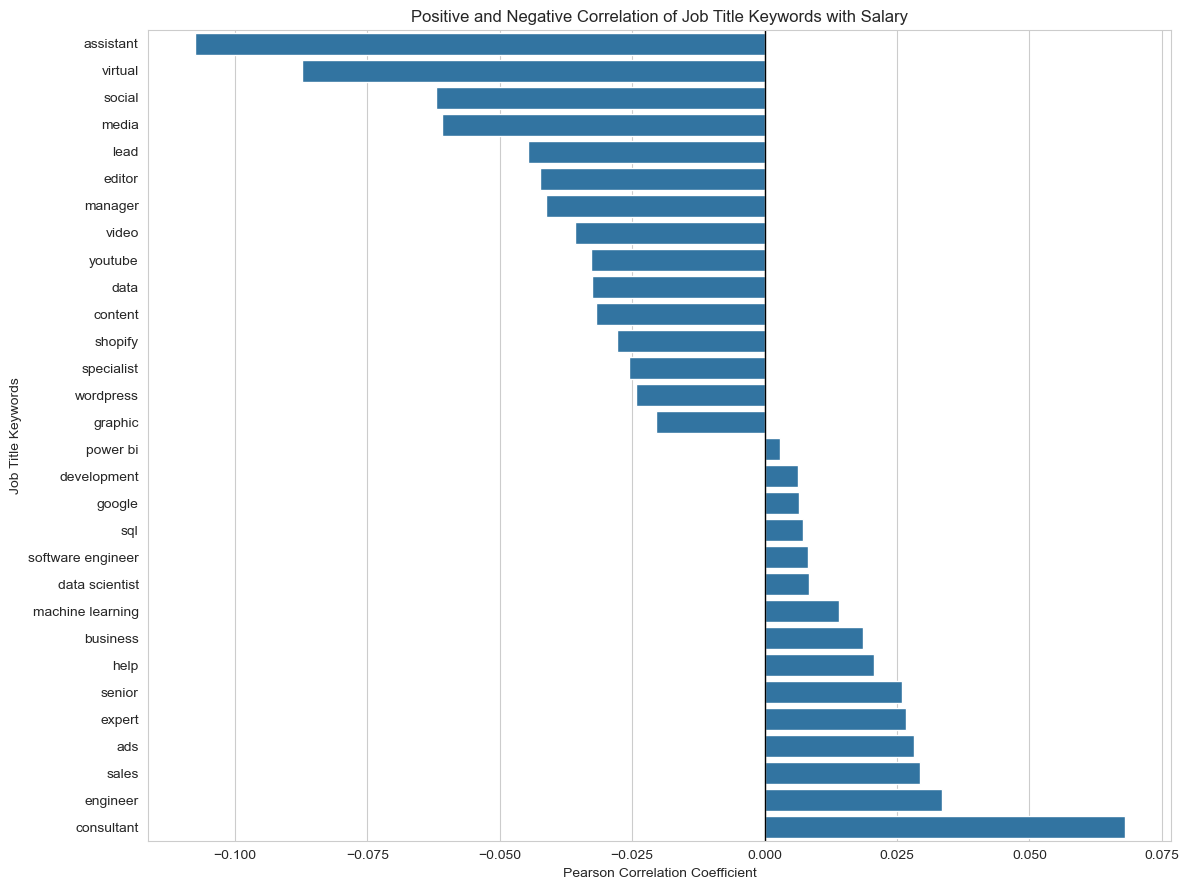

In [151]:
# Correlation visualizations

# Select 15 strongest positive and negative correlations
positive = correlation_df.nlargest(15, 'correlation')
negative = correlation_df.nsmallest(15, 'correlation')

plot_corr = pd.concat([negative, positive])

# Sort for visualization
plot_corr = plot_corr.sort_values('correlation')

plt.figure(figsize=(12, 9))

sns.barplot(
    data=plot_corr,
    x='correlation',
    y='keyword'
)

plt.axvline(0, color='black', linewidth=1)

plt.title('Positive and Negative Correlation of Job Title Keywords with Salary')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Job Title Keywords')

plt.tight_layout()
plt.show()

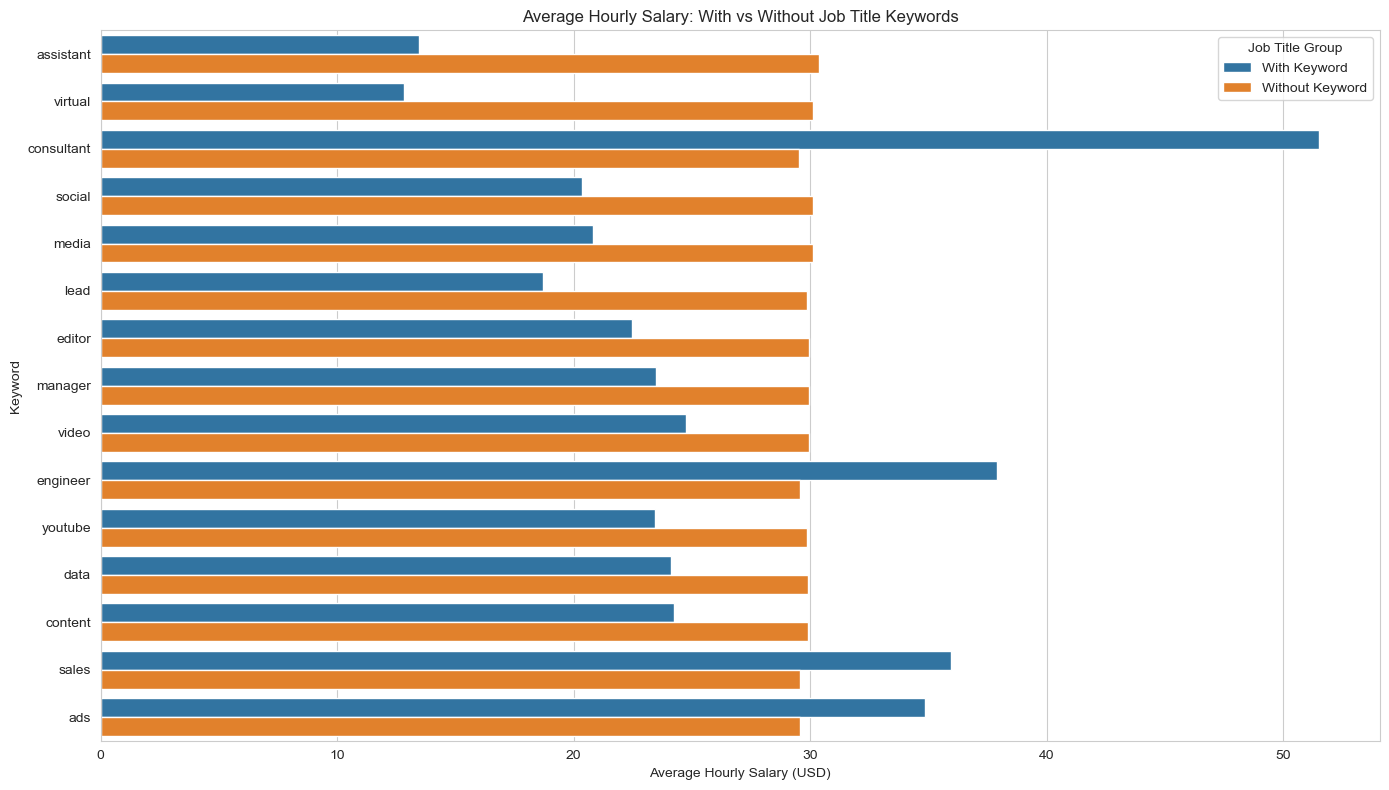

In [152]:
#Compare average salaries with and without keywords

# Select the 15 strongest correlations by absolute magnitude
salary_comparison = correlation_df.reindex(
    correlation_df['correlation'].abs().sort_values(
        ascending=False
    ).index
).head(15)

# Convert to long format
salary_comparison = salary_comparison.melt(
    id_vars='keyword',
    value_vars=[
        'mean_with_keyword',
        'mean_without_keyword'
    ],
    var_name='salary_group',
    value_name='average_salary'
)

# Rename groups
salary_comparison['salary_group'] = (
    salary_comparison['salary_group'].replace({
        'mean_with_keyword': 'With Keyword',
        'mean_without_keyword': 'Without Keyword'
    })
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=salary_comparison,
    x='average_salary',
    y='keyword',
    hue='salary_group'
)

plt.title('Average Hourly Salary: With vs Without Job Title Keywords')
plt.xlabel('Average Hourly Salary (USD)')
plt.ylabel('Keyword')

plt.legend(title='Job Title Group')
plt.tight_layout()
plt.show()

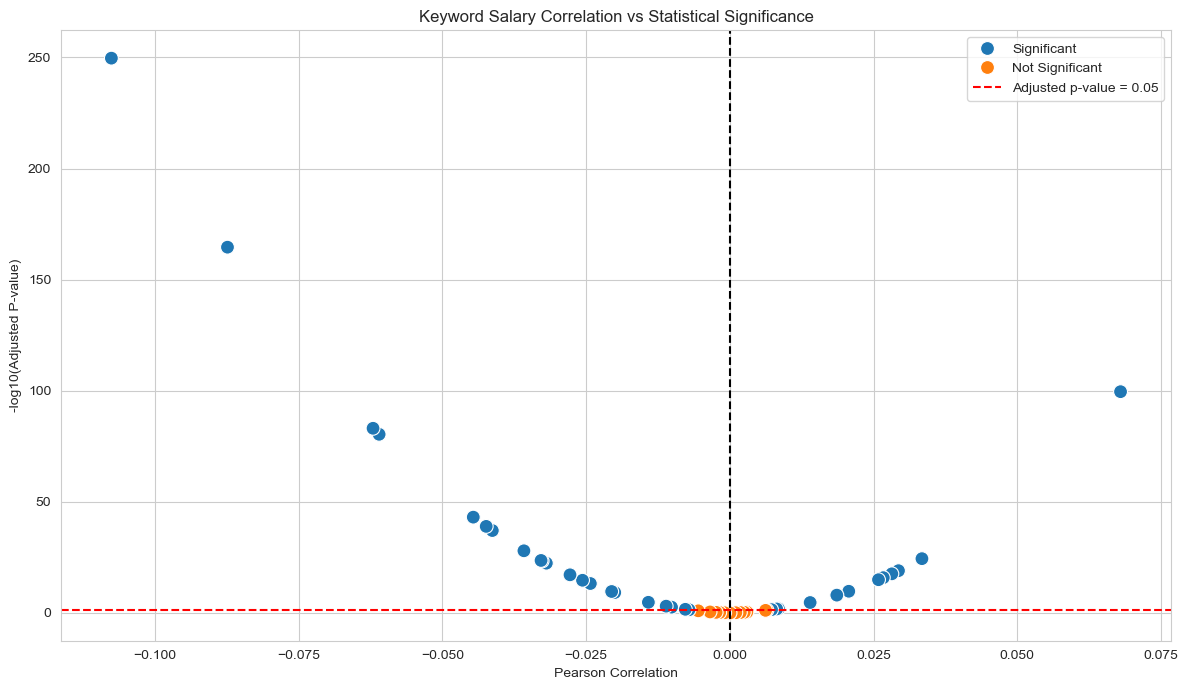

In [153]:
# Visualize correlation against statistical significance

# Prepare visualization data
significance_plot = correlation_df.copy()

# Avoid log(0)
significance_plot['negative_log_p'] = -np.log10(
    significance_plot['adjusted_p_value'].clip(lower=1e-300)
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=significance_plot,
    x='correlation',
    y='negative_log_p',
    hue='adjusted_significance',
    s=100
)

plt.axvline(0, color='black', linestyle='--')
plt.axhline(
    -np.log10(0.05),
    color='red',
    linestyle='--',
    label='Adjusted p-value = 0.05'
)

plt.title('Keyword Salary Correlation vs Statistical Significance')
plt.xlabel('Pearson Correlation')
plt.ylabel('-log10(Adjusted P-value)')

plt.legend()
plt.tight_layout()
plt.show()

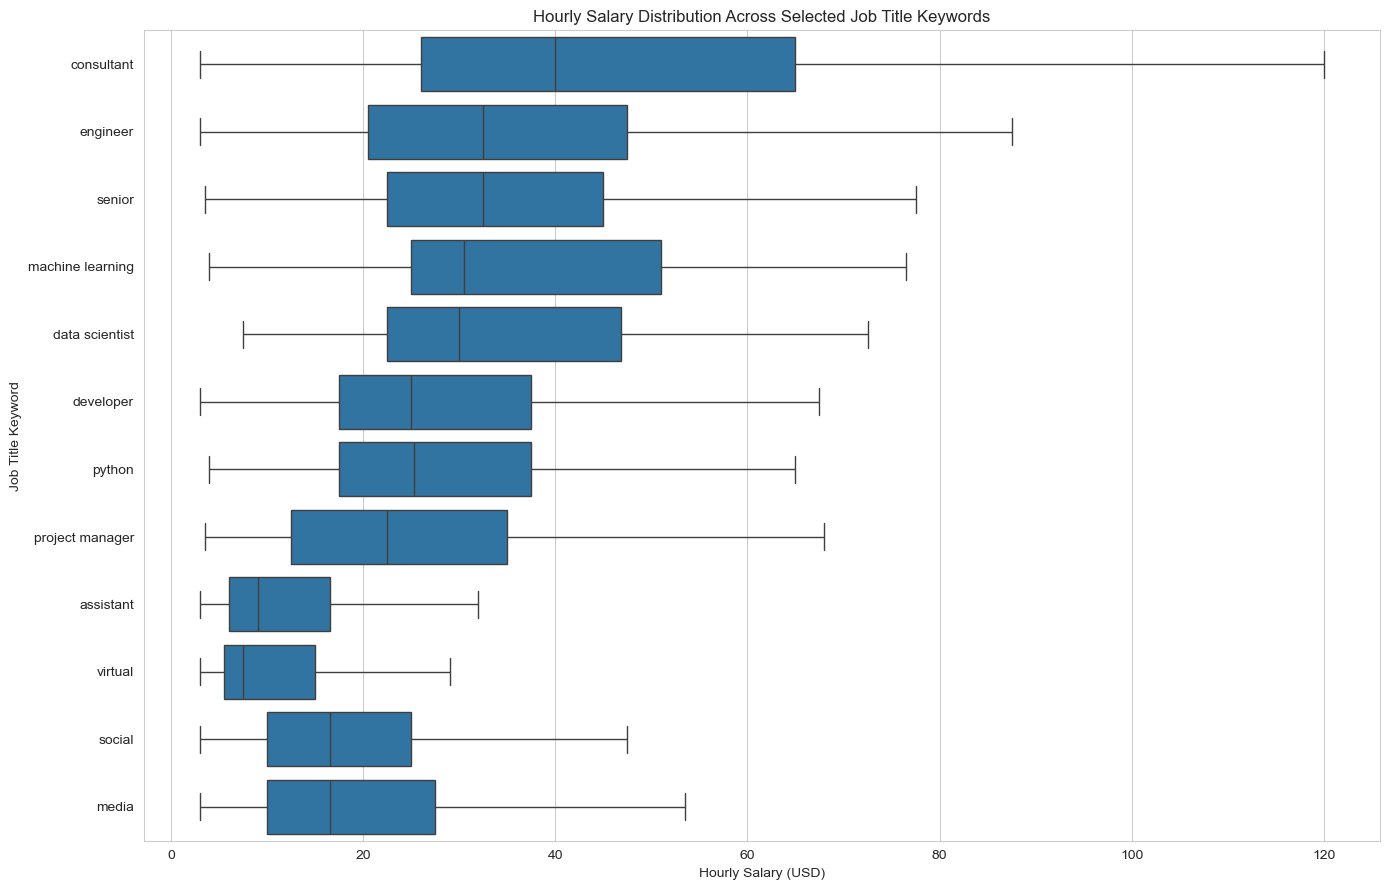

In [154]:
# Compare salary distributions for selected keywords

# Selected keywords for distribution comparison
comparison_keywords = [
    'consultant',
    'engineer',
    'senior',
    'machine learning',
    'data scientist',
    'developer',
    'python',
    'project manager',
    'assistant',
    'virtual',
    'social',
    'media'
]

boxplot_data = []

for keyword in comparison_keywords:

    pattern = rf'(?<!\w){re.escape(keyword)}(?!\w)'

    matched = keyword_df[
        keyword_df['clean_title'].str.contains(
            pattern,
            regex=True,
            na=False
        )
    ].copy()

    matched['keyword'] = keyword

    boxplot_data.append(
        matched[['keyword', 'hourly_midpoint']]
    )

boxplot_df = pd.concat(
    boxplot_data,
    ignore_index=True
)

plt.figure(figsize=(14, 9))

sns.boxplot(
    data=boxplot_df,
    x='hourly_midpoint',
    y='keyword',
    showfliers=False
)

plt.title('Hourly Salary Distribution Across Selected Job Title Keywords')
plt.xlabel('Hourly Salary (USD)')
plt.ylabel('Job Title Keyword')

plt.tight_layout()
plt.show()

# Conclusion: Correlation between job title keywords and offered salaries

The analysis examined the relationship between job-title keywords and offered hourly salaries using approximately 98,775 hourly job postings. Text preprocessing and keyword extraction were performed to identify frequently occurring skills, roles, and job-title terms. Statistical analysis, including Pearson correlation and Benjamini–Hochberg correction, was used to identify significant associations between keywords and salary levels.

The findings revealed that certain specialized and technical keywords were associated with higher average hourly salaries. For example, Consultant had the highest average hourly midpoint of 51.51, followed by Machine Learning at 41.14, Engineer at 37.89, Senior at 37.80, and Data Scientist at 37.74.

In contrast, keywords such as Assistant, Virtual, Social, and Media were associated with lower average hourly salaries. Assistant had an average hourly midpoint of 13.44, while Virtual had an average of 12.84.

The correlation analysis also identified positive associations for Consultant (0.0680), Engineer (0.0334), Sales (0.0293), and Machine Learning (0.0140). Negative associations were observed for Assistant (-0.1076), Virtual (-0.0874), Social (-0.0621), and Media (-0.0610).

Overall, the analysis suggests that specialized expertise, technical skills, and professional experience may be associated with higher salary offerings, whereas administrative and general support-related keywords tend to be associated with lower salary offerings. However, most correlation coefficients were relatively weak, indicating that job-title keywords alone cannot fully explain salary differences.

Conclusion: Job-title keyword analysis provides useful insights into salary patterns in the freelance job market. Specialized roles such as machine learning, engineering, consulting, and data science showed comparatively higher salary levels. These findings can help job seekers identify potentially higher-paying career opportunities and understand how different skills and job roles relate to compensation.

Limitation: The analysis identifies associations rather than causal relationships. Salary differences may also depend on experience, project complexity, client budgets, geographical location, and other factors. The dataset's currency was not explicitly established, so the salary figures are reported as hourly midpoint values without assigning a currency.

### Task 2 – Identify Emerging Job Categories Based on Posting Frequency

In [155]:
# Analyze job posting trends over time

In [156]:
# Create a working copy
trend_df = df.copy()

# Convert published_date to datetime
trend_df['published_date'] = pd.to_datetime(
    trend_df['published_date'],
    errors='coerce',
    utc=True
)

# Check date conversion
print("Dataset Shape:", trend_df.shape)

print("\nMissing Dates:")
print(trend_df['published_date'].isna().sum())

print("\nDate Range:")
print("Start Date:", trend_df['published_date'].min())
print("End Date:", trend_df['published_date'].max())

display(trend_df[['title', 'published_date']].head(10))

Dataset Shape: (244828, 8)

Missing Dates:
0

Date Range:
Start Date: 2023-11-02 09:22:02+00:00
End Date: 2024-03-24 14:16:47+00:00


,title,published_date
0,Experienced Media Buyer For Solar Pannel and Roofing installation companies.,2024-02-17 09:09:54+00:00
1,Full Stack Developer,2024-02-17 09:09:17+00:00
2,SMMA Bubble App,2024-02-17 09:08:46+00:00
3,Talent Hunter Specialized in Marketing,2024-02-17 09:08:08+00:00
4,Data Engineer,2024-02-17 09:07:42+00:00
5,SEO for Portuguese Psychologist site,2024-02-17 09:07:41+00:00
6,Want to fix the WordPress Plugin,2024-02-17 09:07:27+00:00
7,need Portuguese writers who can understand and write Portuguese..,2024-02-17 09:07:05+00:00
8,Looker Studio Dashboard for Leadgen and E-Commerce with Tool &quot;Reporting Ninja&quot;,2024-02-17 09:06:24+00:00
9,PHP/HTML/CSS WordPress Developer Needed for Website Transformation,2024-02-17 09:06:21+00:00


In [157]:
# Extract year, month, and year-month

# Extract date components
trend_df['year'] = trend_df['published_date'].dt.year

trend_df['month'] = trend_df['published_date'].dt.month

trend_df['year_month'] = (
    trend_df['published_date'].dt.to_period('M')
)

trend_df['month_name'] = (
    trend_df['published_date'].dt.month_name()
)

display(
    trend_df[
        ['title', 'published_date', 'year',
         'month', 'year_month', 'month_name']
    ].head(10)
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_10680\1014468843.py:9: UserWarning:

Converting to PeriodArray/Index representation will drop timezone information.



,title,published_date,year,month,year_month,month_name
0,Experienced Media Buyer For Solar Pannel and Roofing installation companies.,2024-02-17 09:09:54+00:00,2024,2,2024-02,February
1,Full Stack Developer,2024-02-17 09:09:17+00:00,2024,2,2024-02,February
2,SMMA Bubble App,2024-02-17 09:08:46+00:00,2024,2,2024-02,February
3,Talent Hunter Specialized in Marketing,2024-02-17 09:08:08+00:00,2024,2,2024-02,February
4,Data Engineer,2024-02-17 09:07:42+00:00,2024,2,2024-02,February
5,SEO for Portuguese Psychologist site,2024-02-17 09:07:41+00:00,2024,2,2024-02,February
6,Want to fix the WordPress Plugin,2024-02-17 09:07:27+00:00,2024,2,2024-02,February
7,need Portuguese writers who can understand and write Portuguese..,2024-02-17 09:07:05+00:00,2024,2,2024-02,February
8,Looker Studio Dashboard for Leadgen and E-Commerce with Tool &quot;Reporting Ninja&quot;,2024-02-17 09:06:24+00:00,2024,2,2024-02,February
9,PHP/HTML/CSS WordPress Developer Needed for Website Transformation,2024-02-17 09:06:21+00:00,2024,2,2024-02,February


In [158]:
# Calculate monthly job posting frequency

# Count job postings for each month
monthly_jobs = (
    trend_df
    .dropna(subset=['published_date'])
    .groupby('year_month')
    .size()
    .reset_index(name='job_count')
)

# Convert period to string for plotting
monthly_jobs['year_month'] = (
    monthly_jobs['year_month'].astype(str)
)

# Display monthly job counts
display(monthly_jobs.head(20))

print("\nTotal Monthly Records:", monthly_jobs['job_count'].sum())

print("\nHighest Posting Month:")
display(
    monthly_jobs.loc[
        monthly_jobs['job_count'].idxmax()
    ]
)

,year_month,job_count
0,2023-11,1
1,2023-12,10
2,2024-01,96
3,2024-02,101887
4,2024-03,142834



Total Monthly Records: 244828

Highest Posting Month:


year_month    2024-03
job_count      142834
Name: 4, dtype: object

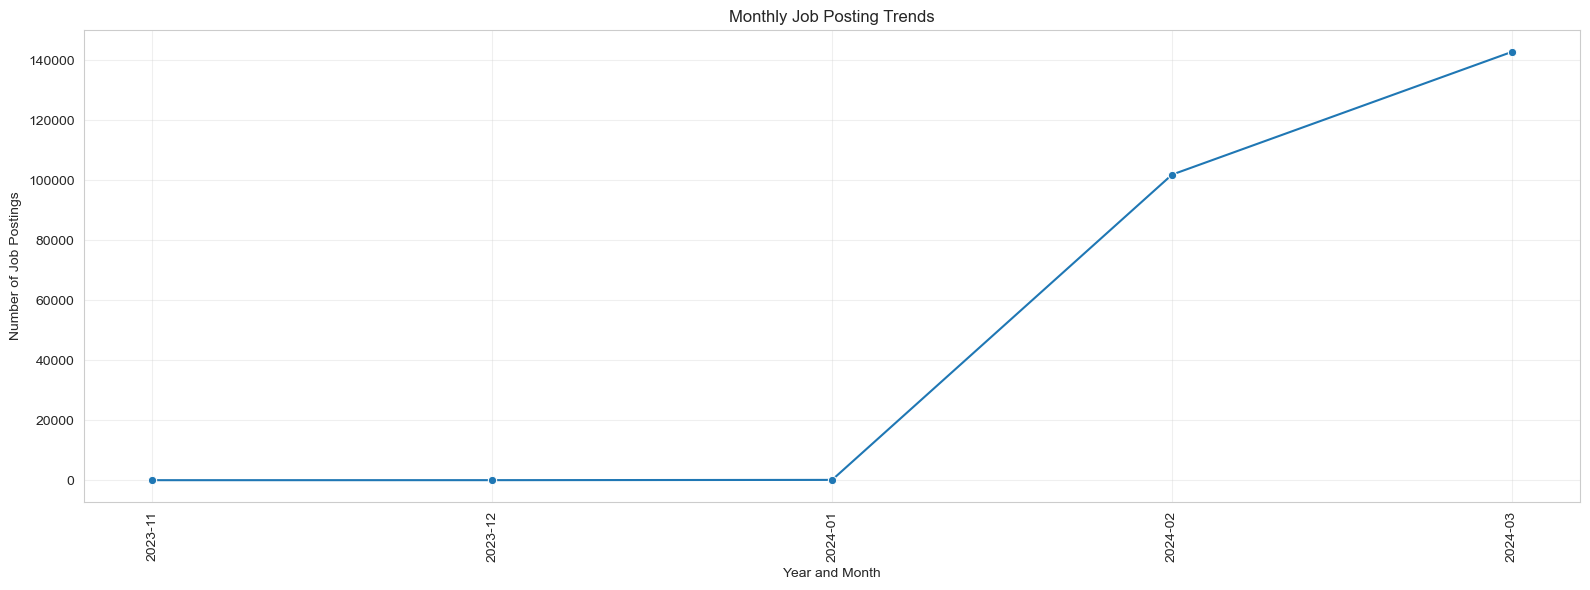

In [159]:
# Visualize monthly job posting trends

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_jobs,
    x='year_month',
    y='job_count',
    marker='o'
)

plt.title('Monthly Job Posting Trends')
plt.xlabel('Year and Month')
plt.ylabel('Number of Job Postings')

plt.xticks(rotation=90)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [160]:
# Calculate monthly growth rate

monthly_jobs['growth_rate'] = (
    monthly_jobs['job_count']
    .pct_change() * 100
)

display(monthly_jobs.round(2))

,year_month,job_count,growth_rate
0,2023-11,1,NaN
1,2023-12,10,900.00
2,2024-01,96,860.00
3,2024-02,101887,106032.29
4,2024-03,142834,40.19


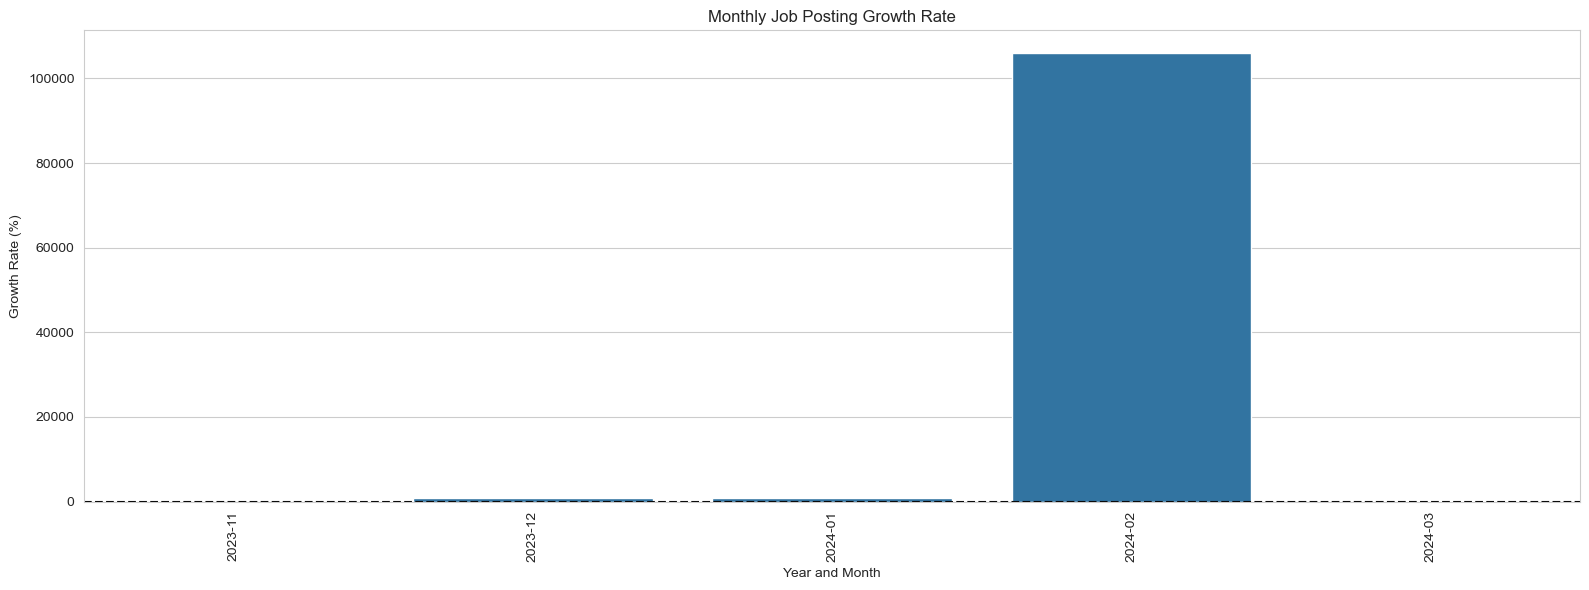

In [161]:
plt.figure(figsize=(16, 6))

sns.barplot(
    data=monthly_jobs,
    x='year_month',
    y='growth_rate'
)

plt.axhline(0, color='black', linestyle='--')

plt.title('Monthly Job Posting Growth Rate')
plt.xlabel('Year and Month')
plt.ylabel('Growth Rate (%)')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [162]:
# Identify job categories from job titles

# Define job categories and their related keywords

job_categories = {
    'Artificial Intelligence & Machine Learning': [
        'machine learning', 'deep learning',
        'artificial intelligence', 'ai engineer',
        'llm', 'generative ai', 'chatgpt',
        'nlp', 'computer vision'
    ],

    'Data Science & Analytics': [
        'data scientist', 'data analyst',
        'data engineer', 'data science',
        'data analytics', 'power bi',
        'tableau', 'sql', 'looker',
        'business intelligence'
    ],

    'Software & Web Development': [
        'developer', 'software engineer',
        'web development', 'full stack',
        'frontend', 'backend', 'wordpress',
        'python developer', 'java developer',
        'php', 'javascript'
    ],

    'Digital Marketing & SEO': [
        'digital marketing', 'seo',
        'social media marketing', 'marketing',
        'google ads', 'facebook ads',
        'email marketing', 'sem', 'ppc'
    ],

    'Graphic & UI/UX Design': [
        'graphic design', 'graphic designer',
        'ui/ux', 'ui design', 'ux design',
        'logo design', 'web designer',
        'illustrator'
    ],

    'Video & Content Creation': [
        'video editing', 'video editor',
        'content creator', 'content writing',
        'youtube', 'animation',
        'motion graphics'
    ],

    'Writing & Translation': [
        'writer', 'writing', 'copywriter',
        'translation', 'translator',
        'proofreading', 'blog writer'
    ],

    'Project Management': [
        'project manager', 'project management',
        'scrum master', 'product manager',
        'project coordinator'
    ],

    'Customer Support & Virtual Assistance': [
        'customer service', 'customer support',
        'virtual assistant', 'administrative assistant',
        'technical support'
    ],

    'E-commerce': [
        'shopify', 'amazon', 'ecommerce',
        'e-commerce', 'woocommerce',
        'product listing'
    ]
}

In [163]:
def classify_job(title):

    if pd.isna(title):
        return 'Other'

    title = str(title).lower()

    for category, keywords in job_categories.items():

        for keyword in keywords:

            pattern = r'\b' + re.escape(keyword) + r'\b'

            if re.search(pattern, title):
                return category

    return 'Other'

In [164]:
# Apply category classification

trend_df['job_category'] = trend_df['title'].apply(
    classify_job
)

# Display classified records

display(
    trend_df[
        ['title', 'job_category']
    ].head(20)
)


,title,job_category
0,Experienced Media Buyer For Solar Pannel and Roofing installation companies.,Other
1,Full Stack Developer,Software & Web Development
2,SMMA Bubble App,Other
3,Talent Hunter Specialized in Marketing,Digital Marketing & SEO
4,Data Engineer,Data Science & Analytics
5,SEO for Portuguese Psychologist site,Digital Marketing & SEO
6,Want to fix the WordPress Plugin,Software & Web Development
7,need Portuguese writers who can understand and write Portuguese..,Other
8,Looker Studio Dashboard for Leadgen and E-Commerce with Tool &quot;Reporting Ninja&quot;,Data Science & Analytics
9,PHP/HTML/CSS WordPress Developer Needed for Website Transformation,Software & Web Development


In [165]:
# Calculate category frequency

category_frequency = (
    trend_df['job_category']
    .value_counts()
    .reset_index()
)

category_frequency.columns = [
    'job_category',
    'job_count'
]

# Calculate percentage

category_frequency['percentage'] = (
    category_frequency['job_count']
    / len(trend_df) * 100
)

display(category_frequency.round(2))

,job_category,job_count,percentage
0,Other,158053,64.56
1,Software & Web Development,23350,9.54
2,Digital Marketing & SEO,15636,6.39
3,Video & Content Creation,14285,5.83
4,Writing & Translation,8993,3.67
5,Graphic & UI/UX Design,8448,3.45
6,E-commerce,7868,3.21
7,Customer Support & Virtual Assistance,4310,1.76
8,Data Science & Analytics,1678,0.69
9,Artificial Intelligence & Machine Learning,1240,0.51


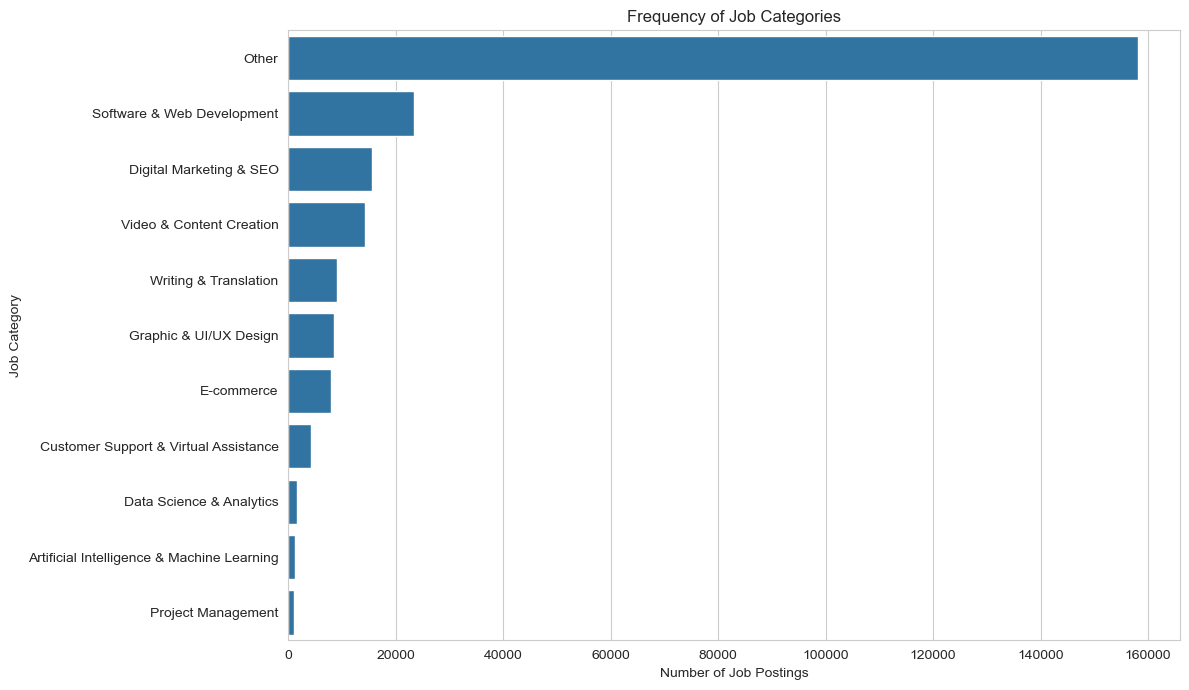

In [166]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_frequency,
    x='job_count',
    y='job_category'
)

plt.title('Frequency of Job Categories')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Category')

plt.tight_layout()
plt.show()

In [167]:
# Improve job category classification

# Extract jobs classified as Other

other_jobs = trend_df[
    trend_df['job_category'] == 'Other'
].copy()

print("Total Other Jobs:", len(other_jobs))

# Display 50 sample titles

display(
    other_jobs['title']
    .sample(min(50, len(other_jobs)), random_state=42)
    .to_frame()
)

Total Other Jobs: 158053


,title
48541,Profile Editor/Proofreader
127659,Pembicara dan Penulis Indonesia untuk Pekerjaan Jarak Jauh
235755,help with Stata and regression model work
191287,Create figma file from existing application screenshots
47941,RSS Feed development
58544,Tax Exempt Filing and S-Corp Conversion with Tax Preparation
240362,Write math test questions 5th graders following template
118542,Resume Customization for Different Job Postings
113500,Hablador o escritor español para publicaciones de novelas
98729,Walmart canada ship setup


In [168]:
# Find frequently occurring words in Other job titles
from sklearn.feature_extraction.text import CountVectorizer

# Remove missing titles
other_titles = other_jobs['title'].fillna('').str.lower()

# Extract frequently occurring words
vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=50
)

word_matrix = vectorizer.fit_transform(other_titles)

word_frequency = pd.DataFrame({
    'keyword': vectorizer.get_feature_names_out(),
    'frequency': word_matrix.sum(axis=0).A1
})

word_frequency = word_frequency.sort_values(
    by='frequency',
    ascending=False
)

display(word_frequency.head(30))

,keyword,frequency
49,website,9557
35,needed,9367
22,expert,8617
13,design,8252
34,need,7008
14,designer,6162
3,app,5504
47,video,5493
2,amp,5471
12,data,5390


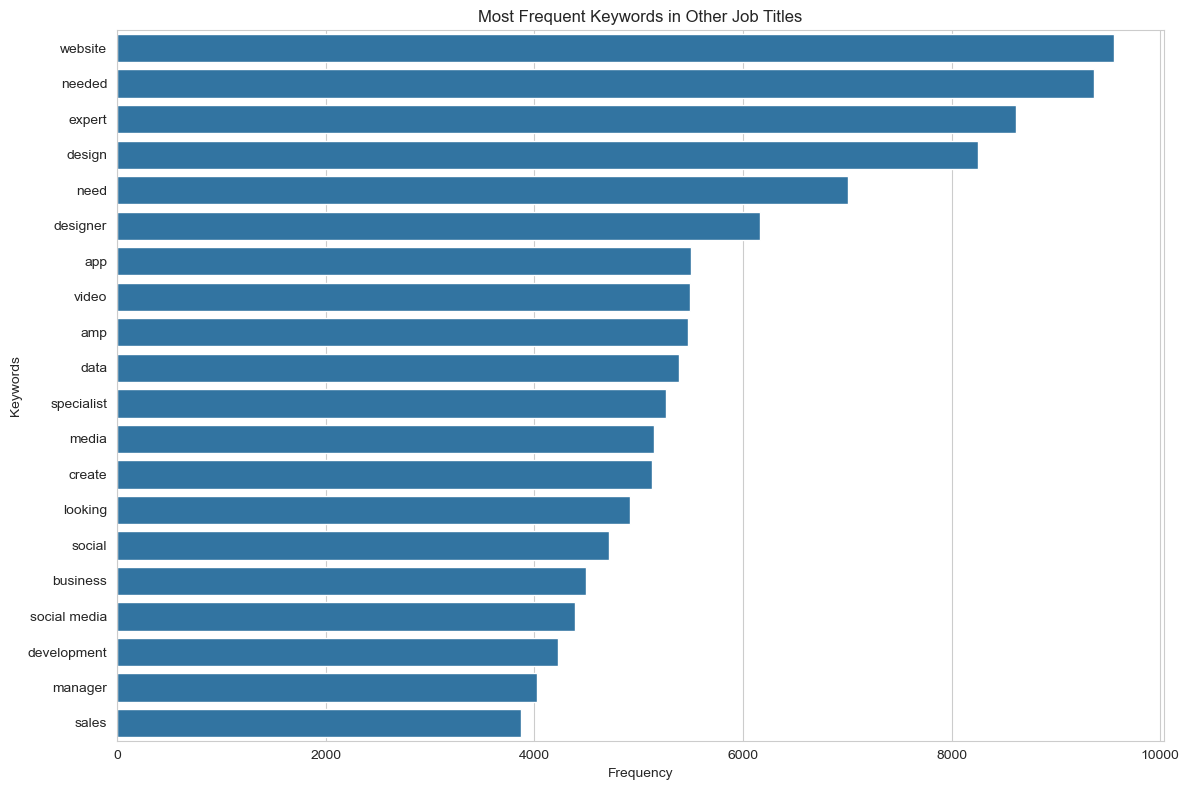

In [169]:
# Visualize unclassified keywords

plt.figure(figsize=(12, 8))

top_words = word_frequency.head(20)

sns.barplot(
    data=top_words,
    x='frequency',
    y='keyword'
)

plt.title('Most Frequent Keywords in Other Job Titles')
plt.xlabel('Frequency')
plt.ylabel('Keywords')

plt.tight_layout()
plt.show()

In [170]:
# Improve job category classification

# Create an expanded category dictionary

expanded_categories = {

    'Artificial Intelligence & Automation': [
        'artificial intelligence', 'machine learning',
        'deep learning', 'generative ai', 'rag application',
        'large language model', 'llm', 'chatgpt',
        'prompt engineering', 'ai automation',
        'manychat', 'chatbot'
    ],

    'Cybersecurity & IT Infrastructure': [
        'cybersecurity', 'cyber security',
        'network security', 'ethical hacking',
        'penetration testing', 'server configuration',
        'smtp server', 'dns', 'cloud security',
        'power mta', 'linux administrator'
    ],

    'Data Science & Analytics': [
        'data scientist', 'data analyst',
        'data engineer', 'data science',
        'data analytics', 'business intelligence',
        'power bi', 'tableau', 'looker studio',
        'machine learning model', 'regression',
        'stata', 'sql', 'excel'
    ],

    'Software & Web Development': [
        'software engineer', 'full stack',
        'frontend', 'front end', 'backend',
        'back end', 'web developer',
        'web development', 'wordpress',
        'javascript', 'python developer',
        'java developer', 'php', 'nestjs',
        'webflow', 'bubble app', 'web application',
        'api development', 'websocket'
    ],

    'E-commerce & Online Marketplace': [
        'ecommerce', 'e-commerce', 'shopify',
        'amazon', 'ebay', 'walmart',
        'woocommerce', 'product listing',
        'online store', 'merchant center'
    ],

    'Digital Marketing & SEO': [
        'digital marketing', 'social media',
        'seo', 'search engine optimization',
        'google ads', 'facebook ads',
        'instagram ads', 'linkedin ads',
        'email marketing', 'affiliate marketing',
        'marketing campaign', 'google search console'
    ],

    'Graphic & UI/UX Design': [
        'graphic design', 'graphic designer',
        'ui/ux', 'ui design', 'ux design',
        'figma', 'logo design', 'web designer',
        'illustrator', '3d design', '3d model'
    ],

    'Video & Content Creation': [
        'video editing', 'video editor',
        'video production', 'content creator',
        'content creation', 'youtube video',
        'animation', 'motion graphics',
        'ad film'
    ],

    'Writing, Translation & Editing': [
        'writer', 'writing', 'copywriter',
        'proofreading', 'proofreader',
        'translation', 'translator',
        'content writing', 'blog writer',
        'resume writing', 'beta reader',
        'editor', 'book editing'
    ],

    'Project & Product Management': [
        'project manager', 'project management',
        'project coordinator', 'scrum master',
        'product manager', 'product management'
    ],

    'Customer Support & CRM': [
        'customer service', 'customer support',
        'technical support', 'intercom',
        'crm', 'customer relationship management',
        'client support'
    ],

    'Virtual Assistance & Administration': [
        'virtual assistant', 'executive assistant',
        'administrative assistant', 'data entry',
        'file management', 'appointment setting',
        'google drive', 'office assistant'
    ],

    'Sales & Business Development': [
        'business development', 'sales manager',
        'sales representative', 'sales executive',
        'lead generation', 'appointment setter',
        'closer', 'business consultant'
    ],

    'Finance, Accounting & Tax': [
        'accounting', 'accountant',
        'bookkeeping', 'tax preparation',
        'tax filing', 'financial analysis',
        'financial modeling', 'payroll',
        's-corp', 'invoice management'
    ],

    'Legal & Documentation Services': [
        'legal services', 'legal research',
        'foia', 'legal document',
        'marriage certificate', 'certificate of ownership',
        'contract drafting', 'paralegal'
    ],

    'Education & Research': [
        'online tutor', 'tutoring',
        'teacher', 'teaching',
        'math test', 'test questions',
        'academic research', 'research assistant',
        'stata regression'
    ],

    'HR & Recruitment': [
        'recruitment', 'recruiter',
        'talent acquisition', 'talent hunter',
        'human resources', 'hr manager',
        'resume screening'
    ]
}

In [171]:
# Update the classification function

def classify_job(title):

    if pd.isna(title):
        return 'Other'

    title = html.unescape(str(title)).lower().strip()

    for category, keywords in expanded_categories.items():

        for keyword in keywords:

            pattern = r'\b' + re.escape(keyword) + r'\b'

            if re.search(pattern, title):
                return category

    return 'Other'

In [172]:
# Apply the improved classification

trend_df['job_category'] = trend_df['title'].apply(
    classify_job
)

# Calculate updated category frequency

category_frequency = (
    trend_df['job_category']
    .value_counts()
    .reset_index()
)

category_frequency.columns = [
    'job_category',
    'job_count'
]

category_frequency['percentage'] = (
    category_frequency['job_count']
    / len(trend_df) * 100
)

display(category_frequency.round(2))

,job_category,job_count,percentage
0,Other,150932,61.65
1,Digital Marketing & SEO,16004,6.54
2,Software & Web Development,14619,5.97
3,"Writing, Translation & Editing",12243,5.00
4,E-commerce & Online Marketplace,10930,4.46
5,Graphic & UI/UX Design,9401,3.84
6,Video & Content Creation,8905,3.64
7,Virtual Assistance & Administration,5006,2.04
8,Sales & Business Development,4469,1.83
9,Data Science & Analytics,3670,1.50


In [173]:
# Check improvement in Other category

other_count = (
    trend_df['job_category'] == 'Other'
).sum()

other_percentage = (
    other_count / len(trend_df) * 100
)

print("Total Jobs:", len(trend_df))

print("Unclassified Jobs:", other_count)

print(
    "Unclassified Percentage:",
    round(other_percentage, 2), "%"
)

Total Jobs: 244828
Unclassified Jobs: 150932
Unclassified Percentage: 61.65 %


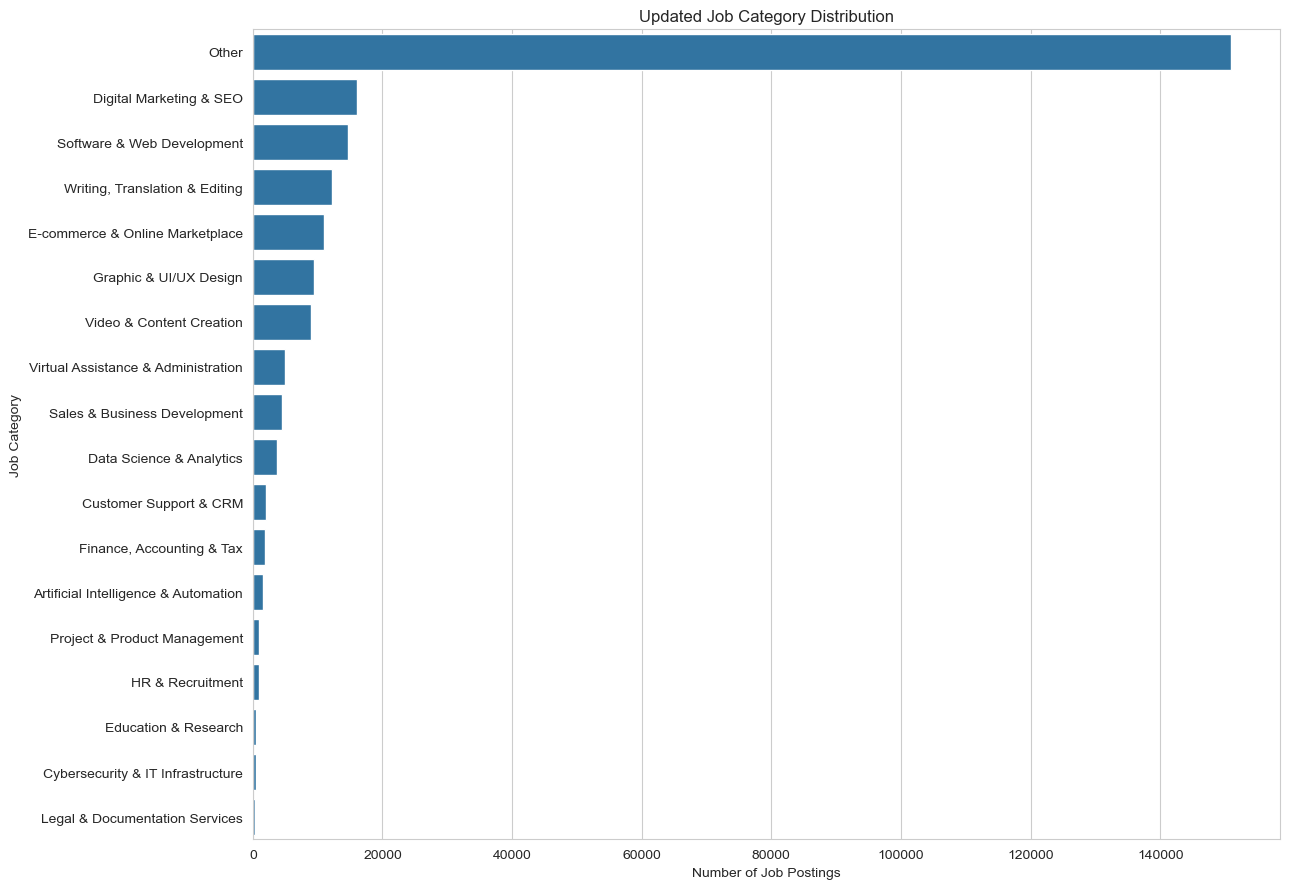

In [174]:
# Visualize updated categories

plt.figure(figsize=(13, 9))

sns.barplot(
    data=category_frequency,
    x='job_count',
    y='job_category'
)

plt.title('Updated Job Category Distribution')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Category')

plt.tight_layout()
plt.show()

In [175]:
# Monthly job posting frequency by category

# Prepare monthly category data
# Create a working copy
category_trend_df = trend_df.copy()

# Remove records with missing dates
category_trend_df = category_trend_df.dropna(
    subset=['published_date']
)

# Extract year-month
category_trend_df['year_month'] = (
    category_trend_df['published_date']
    .dt.to_period('M')
)

# Calculate monthly job counts by category
monthly_category = (
    category_trend_df
    .groupby(['year_month', 'job_category'])
    .size()
    .reset_index(name='job_count')
)

display(monthly_category.head(20))

C:\Users\Admin\AppData\Local\Temp\ipykernel_10680\4276730565.py:15: UserWarning:

Converting to PeriodArray/Index representation will drop timezone information.



,year_month,job_category,job_count
0,2023-11,Other,1
1,2023-12,Data Science & Analytics,1
2,2023-12,E-commerce & Online Marketplace,1
3,2023-12,"Finance, Accounting & Tax",1
4,2023-12,HR & Recruitment,1
5,2023-12,Other,4
6,2023-12,"Writing, Translation & Editing",2
7,2024-01,Artificial Intelligence & Automation,2
8,2024-01,Customer Support & CRM,7
9,2024-01,Cybersecurity & IT Infrastructure,1


In [176]:
# Create a monthly category pivot table
category_pivot = monthly_category.pivot(
    index='job_category',
    columns='year_month',
    values='job_count'
).fillna(0)

# Convert counts to integers
category_pivot = category_pivot.astype(int)

display(category_pivot)

year_month,2023-11,2023-12,2024-01,2024-02,2024-03
job_category,,,,,
Artificial Intelligence & Automation,0,0,2,634,952
Customer Support & CRM,0,0,7,804,1151
Cybersecurity & IT Infrastructure,0,0,1,172,269
Data Science & Analytics,0,1,1,1531,2137
Digital Marketing & SEO,0,0,5,6481,9518
E-commerce & Online Marketplace,0,1,4,4488,6437
Education & Research,0,0,0,212,302
"Finance, Accounting & Tax",0,1,3,801,1132
Graphic & UI/UX Design,0,0,0,3818,5583


In [177]:
# Calculate month-over-month growth rates
# Sort monthly columns
category_pivot = category_pivot.sort_index(axis=1)

# Calculate percentage growth
category_growth = category_pivot.pct_change(
    axis=1
) * 100

# Replace infinite values
category_growth = category_growth.replace(
    [np.inf, -np.inf],
    np.nan
)

display(category_growth.round(2))

year_month,2023-11,2023-12,2024-01,2024-02,2024-03
job_category,,,,,
Artificial Intelligence & Automation,NaN,NaN,NaN,31600.00,50.16
Customer Support & CRM,NaN,NaN,NaN,11385.71,43.16
Cybersecurity & IT Infrastructure,NaN,NaN,NaN,17100.00,56.40
Data Science & Analytics,NaN,NaN,0.0,153000.00,39.58
Digital Marketing & SEO,NaN,NaN,NaN,129520.00,46.86
E-commerce & Online Marketplace,NaN,NaN,300.0,112100.00,43.43
Education & Research,NaN,NaN,NaN,NaN,42.45
"Finance, Accounting & Tax",NaN,NaN,200.0,26600.00,41.32
Graphic & UI/UX Design,NaN,NaN,NaN,NaN,46.23


In [178]:
# Compare February and March category growth
feb_col = pd.Period('2024-02', freq='M')
mar_col = pd.Period('2024-03', freq='M')

growth_comparison = pd.DataFrame({
    'February_Jobs': category_pivot[feb_col],
    'March_Jobs': category_pivot[mar_col]
})

growth_comparison['Growth_Rate'] = (
    (
        growth_comparison['March_Jobs']
        - growth_comparison['February_Jobs']
    )
    / growth_comparison['February_Jobs'].replace(0, np.nan)
) * 100

growth_comparison = (
    growth_comparison
    .sort_values('Growth_Rate', ascending=False)
)

display(growth_comparison.round(2))

,February_Jobs,March_Jobs,Growth_Rate
job_category,,,
Cybersecurity & IT Infrastructure,172,269,56.40
Sales & Business Development,1772,2692,51.92
Video & Content Creation,3551,5353,50.75
Artificial Intelligence & Automation,634,952,50.16
Project & Product Management,389,576,48.07
Digital Marketing & SEO,6481,9518,46.86
Graphic & UI/UX Design,3818,5583,46.23
HR & Recruitment,375,541,44.27
E-commerce & Online Marketplace,4488,6437,43.43


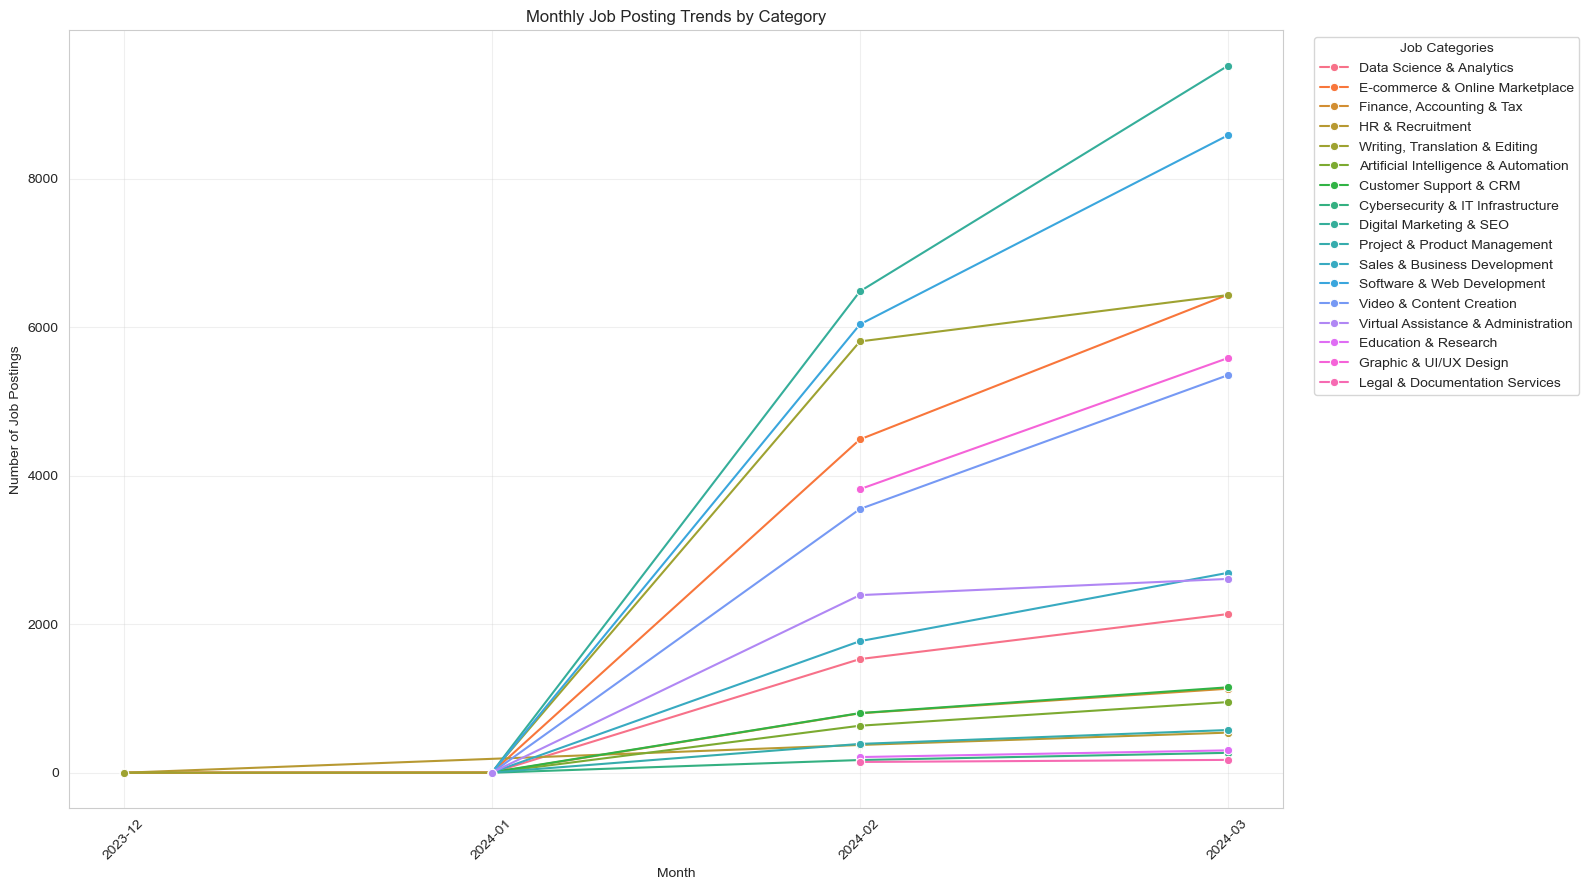

In [179]:
# Visualize monthly posting trends by category

# Prepare data for plotting
monthly_plot = monthly_category.copy()

monthly_plot['year_month'] = (
    monthly_plot['year_month'].astype(str)
)

plt.figure(figsize=(16, 9))

sns.lineplot(
    data=monthly_plot[
        monthly_plot['job_category'] != 'Other'
    ],
    x='year_month',
    y='job_count',
    hue='job_category',
    marker='o'
)

plt.title('Monthly Job Posting Trends by Category')
plt.xlabel('Month')
plt.ylabel('Number of Job Postings')

plt.xticks(rotation=45)
plt.legend(
    title='Job Categories',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

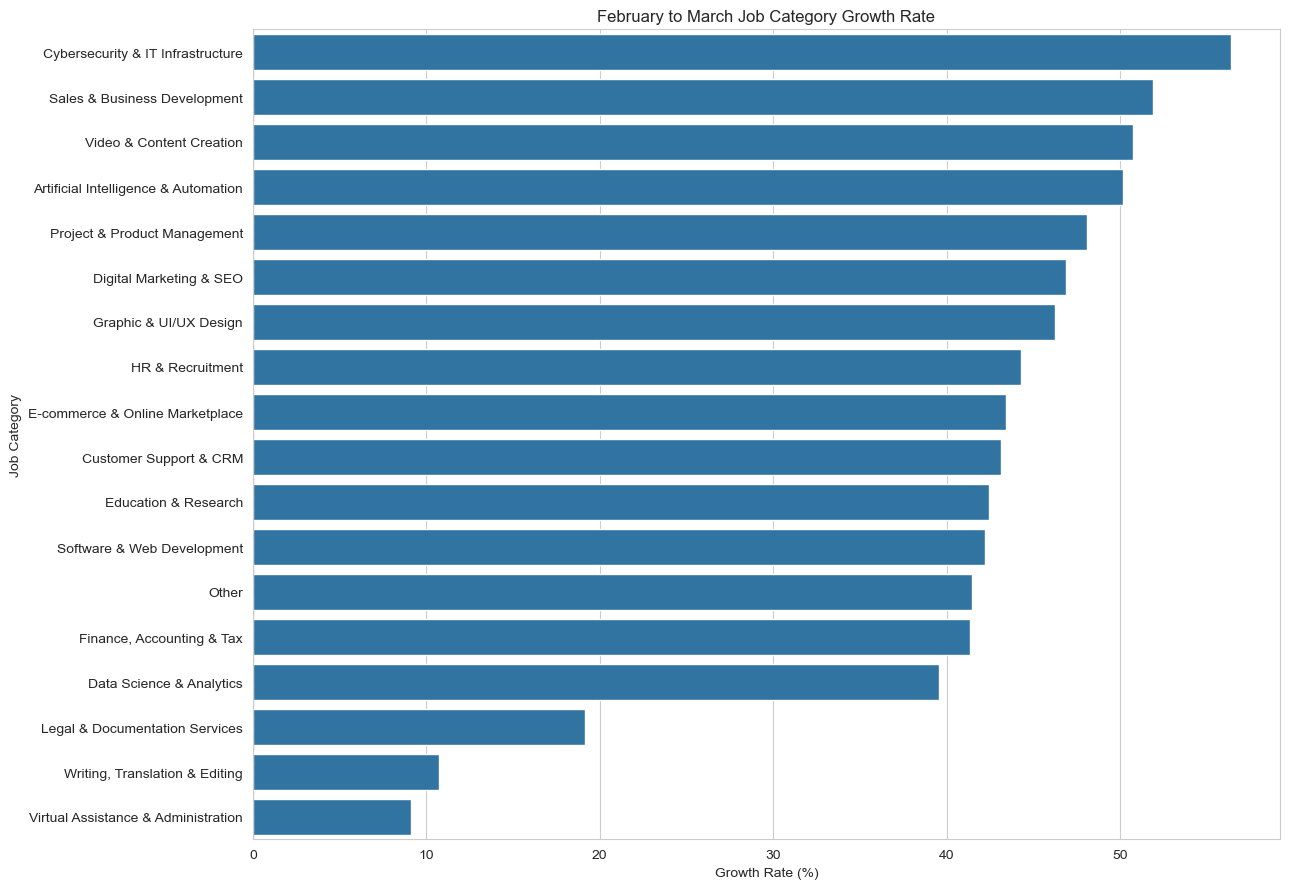

In [180]:
# Visualize category growth rates

growth_plot = (
    growth_comparison
    .dropna(subset=['Growth_Rate'])
    .reset_index()
)

plt.figure(figsize=(13, 9))

sns.barplot(
    data=growth_plot,
    x='Growth_Rate',
    y='job_category'
)

plt.axvline(
    0,
    color='black',
    linestyle='--'
)

plt.title(
    'February to March Job Category Growth Rate'
)

plt.xlabel('Growth Rate (%)')
plt.ylabel('Job Category')

plt.tight_layout()
plt.show()

In [181]:
# Calculate daily posting rates and adjusted growth

# Calculate daily posting rates
days_observed = {
    pd.Period('2024-02', freq='M'): 29,
    pd.Period('2024-03', freq='M'): 24
}

daily_rates = pd.DataFrame(index=category_pivot.index)

daily_rates['February_Daily_Average'] = (
    category_pivot[pd.Period('2024-02', freq='M')] / 29
)

daily_rates['March_Daily_Average'] = (
    category_pivot[pd.Period('2024-03', freq='M')] / 24
)

# Calculate adjusted growth
daily_rates['Daily_Growth_Rate'] = (
    (
        daily_rates['March_Daily_Average']
        - daily_rates['February_Daily_Average']
    )
    / daily_rates['February_Daily_Average'].replace(0, np.nan)
) * 100

daily_rates = daily_rates.sort_values(
    'Daily_Growth_Rate',
    ascending=False
)

display(daily_rates.round(2))


,February_Daily_Average,March_Daily_Average,Daily_Growth_Rate
job_category,,,
Cybersecurity & IT Infrastructure,5.93,11.21,88.98
Sales & Business Development,61.10,112.17,83.57
Video & Content Creation,122.45,223.04,82.15
Artificial Intelligence & Automation,21.86,39.67,81.44
Project & Product Management,13.41,24.00,78.92
Digital Marketing & SEO,223.48,396.58,77.46
Graphic & UI/UX Design,131.66,232.62,76.69
HR & Recruitment,12.93,22.54,74.32
E-commerce & Online Marketplace,154.76,268.21,73.31


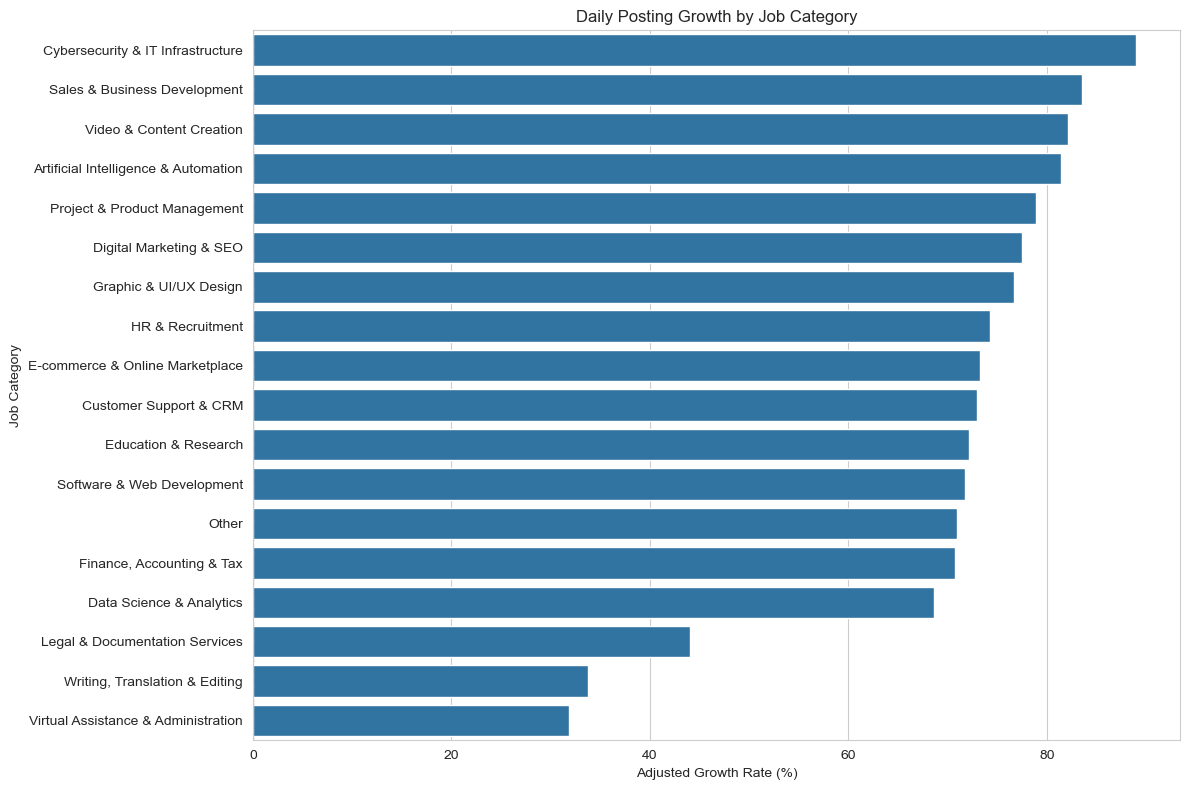

In [182]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=daily_rates.reset_index(),
    x='Daily_Growth_Rate',
    y='job_category'
)

plt.axvline(0, color='black', linestyle='--')
plt.title('Daily Posting Growth by Job Category')
plt.xlabel('Adjusted Growth Rate (%)')
plt.ylabel('Job Category')
plt.tight_layout()
plt.show()

In [183]:
# Identify the strongest opportunities by volume and growth

# Add absolute daily increase
daily_rates['Daily_Increase'] = (
    daily_rates['March_Daily_Average']
    - daily_rates['February_Daily_Average']
)

# Exclude Other because it is a broad, unclassified group
emerging_categories = daily_rates.drop(
    index='Other',
    errors='ignore'
).sort_values(
    'Daily_Increase',
    ascending=False
)

display(
    emerging_categories[
        [
            'February_Daily_Average',
            'March_Daily_Average',
            'Daily_Increase',
            'Daily_Growth_Rate'
        ]
    ].round(2)
)

,February_Daily_Average,March_Daily_Average,Daily_Increase,Daily_Growth_Rate
job_category,,,,
Digital Marketing & SEO,223.48,396.58,173.10,77.46
Software & Web Development,208.14,357.58,149.45,71.80
E-commerce & Online Marketplace,154.76,268.21,113.45,73.31
Graphic & UI/UX Design,131.66,232.62,100.97,76.69
Video & Content Creation,122.45,223.04,100.59,82.15
"Writing, Translation & Editing",200.24,267.96,67.72,33.82
Sales & Business Development,61.10,112.17,51.06,83.57
Data Science & Analytics,52.79,89.04,36.25,68.66
Virtual Assistance & Administration,82.48,108.75,26.27,31.85


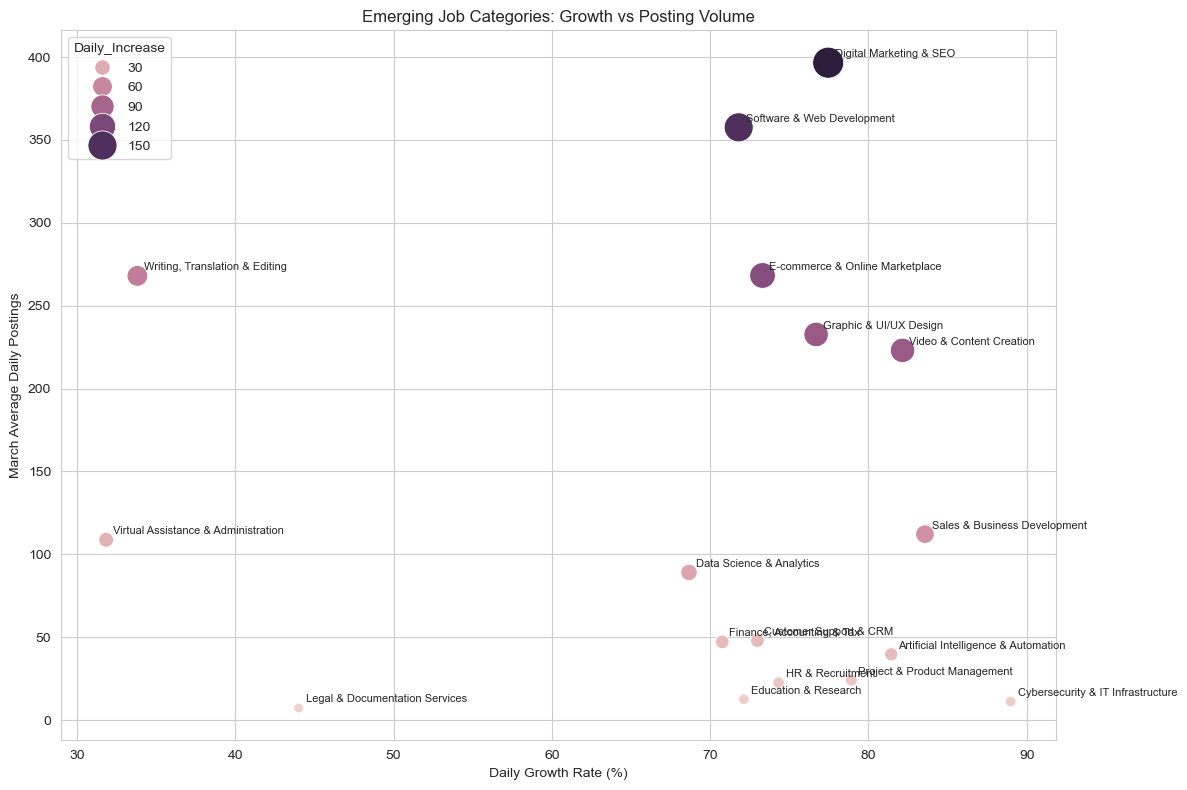

In [184]:
chart_data = emerging_categories.reset_index()

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=chart_data,
    x='Daily_Growth_Rate',
    y='March_Daily_Average',
    size='Daily_Increase',
    hue='Daily_Increase',
    sizes=(50, 500),
    legend='brief'
)

for _, row in chart_data.iterrows():
    plt.annotate(
        row['job_category'],
        (row['Daily_Growth_Rate'], row['March_Daily_Average']),
        fontsize=8,
        xytext=(5, 4),
        textcoords='offset points'
    )

plt.title('Emerging Job Categories: Growth vs Posting Volume')
plt.xlabel('Daily Growth Rate (%)')
plt.ylabel('March Average Daily Postings')
plt.tight_layout()
plt.show()

# Conclusion: Identification of Emerging Job Categories

The analysis of job postings from November 2023 to March 2024 revealed increasing demand across all identified job categories. To account for the incomplete month of March, average daily posting rates were calculated for February and March 2024.

Digital Marketing & SEO recorded the largest increase, with an additional 173.10 average daily postings and a growth rate of 77.46%. Software & Web Development followed with an increase of 149.45 daily postings and 71.80% growth. E-commerce & Online Marketplace, Graphic & UI/UX Design, and Video & Content Creation also demonstrated substantial increases in posting activity.

Some smaller categories showed particularly high percentage growth. Cybersecurity & IT Infrastructure recorded the highest growth rate at 88.98%, followed by Sales & Business Development at 83.57%, Video & Content Creation at 82.15%, and Artificial Intelligence & Automation at 81.44%.

Overall, Digital Marketing & SEO and Software & Web Development represented the strongest opportunities in terms of posting volume and absolute growth. Meanwhile, AI & Automation and Cybersecurity showed promising growth rates from smaller starting volumes.

These findings indicate growing demand across several digital, technical, creative, and business-related skill areas during the observed period. However, the results represent a short observation window and rely on keyword-based job categorization. Therefore, they should be interpreted as potential emerging trends rather than confirmed long-term industry trends.

# Task 3: Predict high-demand job roles by analyzing job posting patterns over time

In [185]:
# Prepare weekly job demand data

# Create a copy of the dataset
forecast_df = trend_df.copy()

# Convert dates to datetime
forecast_df['published_date'] = pd.to_datetime(
    forecast_df['published_date'],
    errors='coerce',
    utc=True
)

# Remove rows with missing dates or categories
forecast_df = forecast_df.dropna(
    subset=['published_date', 'job_category']
)

# Convert dates to weekly periods
forecast_df['week'] = (
    forecast_df['published_date']
    .dt.tz_convert(None)
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

# Count postings per category per week
weekly_demand = (
    forecast_df.groupby(['week', 'job_category'])
    .size()
    .reset_index(name='job_count')
)

# Create category-wise time series
weekly_pivot = weekly_demand.pivot(
    index='week',
    columns='job_category',
    values='job_count'
).fillna(0)

weekly_pivot = weekly_pivot.sort_index().astype(int)

print("Weekly demand dataset shape:", weekly_pivot.shape)

display(weekly_pivot.head(10))
display(weekly_pivot.tail(10))

Weekly demand dataset shape: (18, 18)


job_category,Artificial Intelligence & Automation,Customer Support & CRM,Cybersecurity & IT Infrastructure,Data Science & Analytics,Digital Marketing & SEO,E-commerce & Online Marketplace,Education & Research,"Finance, Accounting & Tax",Graphic & UI/UX Design,HR & Recruitment,Legal & Documentation Services,Other,Project & Product Management,Sales & Business Development,Software & Web Development,Video & Content Creation,Virtual Assistance & Administration,"Writing, Translation & Editing"
week,,,,,,,,,,,,,,,,,,
2023-10-30,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2023-11-27,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2023-12-04,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2023-12-11,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1
2023-12-18,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2023-12-25,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,1
2024-01-01,0,0,0,0,0,0,0,0,0,0,0,4,0,1,0,0,2,0
2024-01-08,0,1,0,0,0,0,0,0,0,0,0,5,1,0,0,1,0,0
2024-01-15,0,2,0,0,2,0,0,1,0,0,0,10,1,0,0,0,0,2


job_category,Artificial Intelligence & Automation,Customer Support & CRM,Cybersecurity & IT Infrastructure,Data Science & Analytics,Digital Marketing & SEO,E-commerce & Online Marketplace,Education & Research,"Finance, Accounting & Tax",Graphic & UI/UX Design,HR & Recruitment,Legal & Documentation Services,Other,Project & Product Management,Sales & Business Development,Software & Web Development,Video & Content Creation,Virtual Assistance & Administration,"Writing, Translation & Editing"
week,,,,,,,,,,,,,,,,,,
2024-01-15,0,2,0,0,2,0,0,1,0,0,0,10,1,0,0,0,0,2
2024-01-22,1,0,0,1,3,2,0,1,0,0,0,16,2,2,0,0,2,1
2024-01-29,2,4,1,1,5,2,0,1,0,0,1,38,0,3,3,3,1,3
2024-02-05,0,2,0,1,11,7,0,1,3,0,0,66,1,3,5,1,2,6
2024-02-12,173,238,54,424,1805,1297,49,225,1082,115,39,17369,113,502,1704,980,665,1533
2024-02-19,281,362,74,725,2827,1921,106,339,1699,151,70,27704,173,742,2624,1571,1192,2983
2024-02-26,276,315,70,611,2855,1996,88,362,1648,148,53,27270,159,796,2635,1589,804,1969
2024-03-04,279,371,84,652,2978,1931,113,353,1709,185,58,27031,188,767,2609,1653,819,1939
2024-03-11,294,319,83,629,2879,1928,71,341,1687,164,52,26443,174,846,2599,1630,826,2043


<Figure size 1600x800 with 0 Axes>

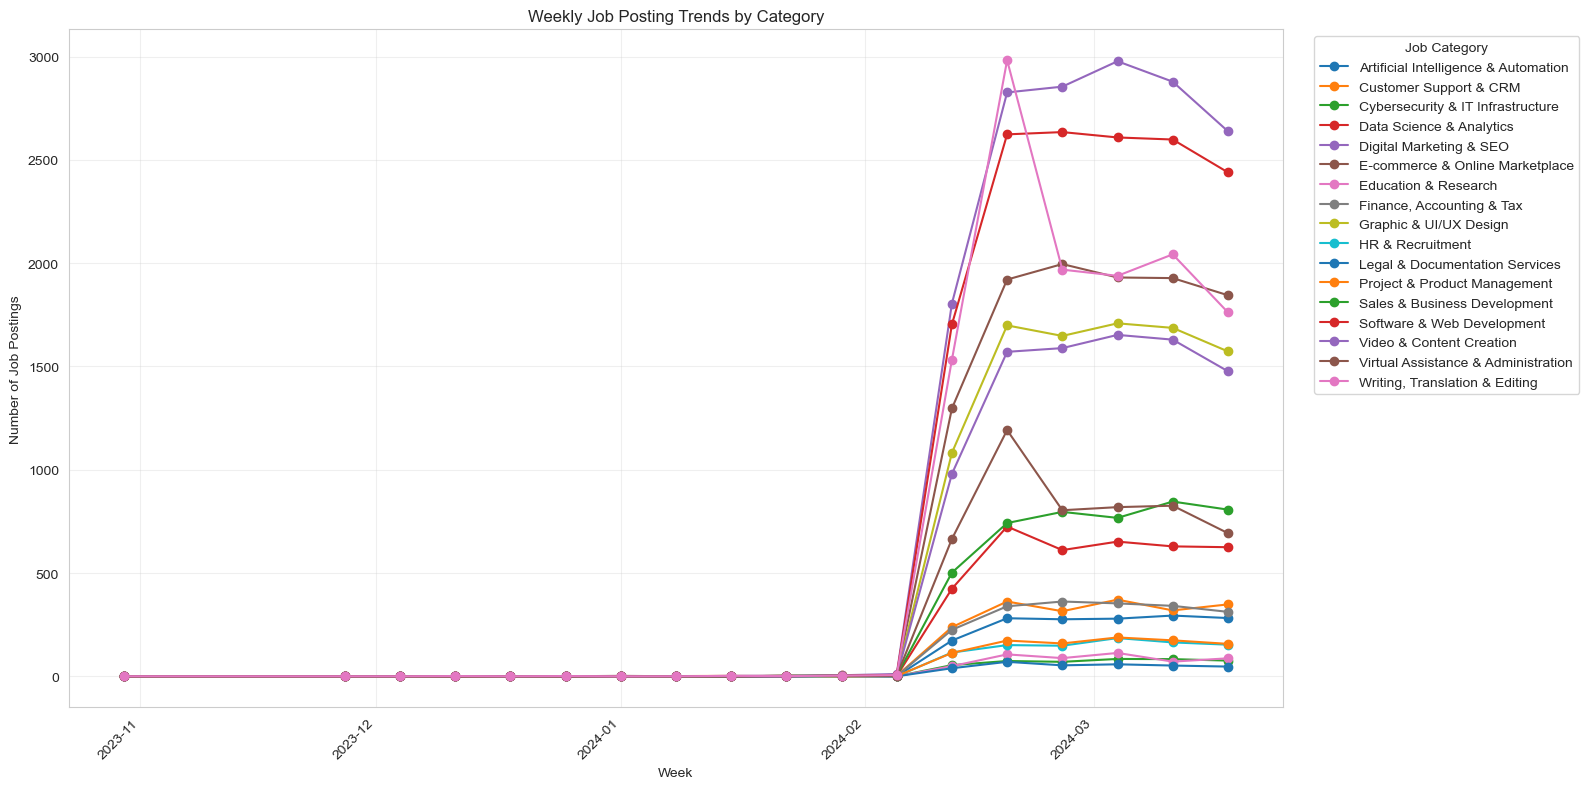

In [186]:
plt.figure(figsize=(16, 8))

weekly_pivot.drop(
    columns=['Other'],
    errors='ignore'
).plot(
    figsize=(16, 8),
    marker='o'
)

plt.title('Weekly Job Posting Trends by Category')
plt.xlabel('Week')
plt.ylabel('Number of Job Postings')
plt.xticks(rotation=45)
plt.legend(
    title='Job Category',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [187]:
# Analyze total weekly posting patterns

# Calculate total postings per week
weekly_total = weekly_pivot.sum(axis=1)

weekly_summary = pd.DataFrame({
    'week': weekly_total.index,
    'total_jobs': weekly_total.values
})

# Calculate week-over-week change
weekly_summary['weekly_change'] = (
    weekly_summary['total_jobs'].pct_change() * 100
)

display(weekly_summary.round(2))

,week,total_jobs,weekly_change
0,2023-10-30,1,NaN
1,2023-11-27,1,0.00
2,2023-12-04,1,0.00
3,2023-12-11,3,200.00
4,2023-12-18,2,-33.33
5,2023-12-25,3,50.00
6,2024-01-01,7,133.33
7,2024-01-08,8,14.29
8,2024-01-15,18,125.00
9,2024-01-22,31,72.22


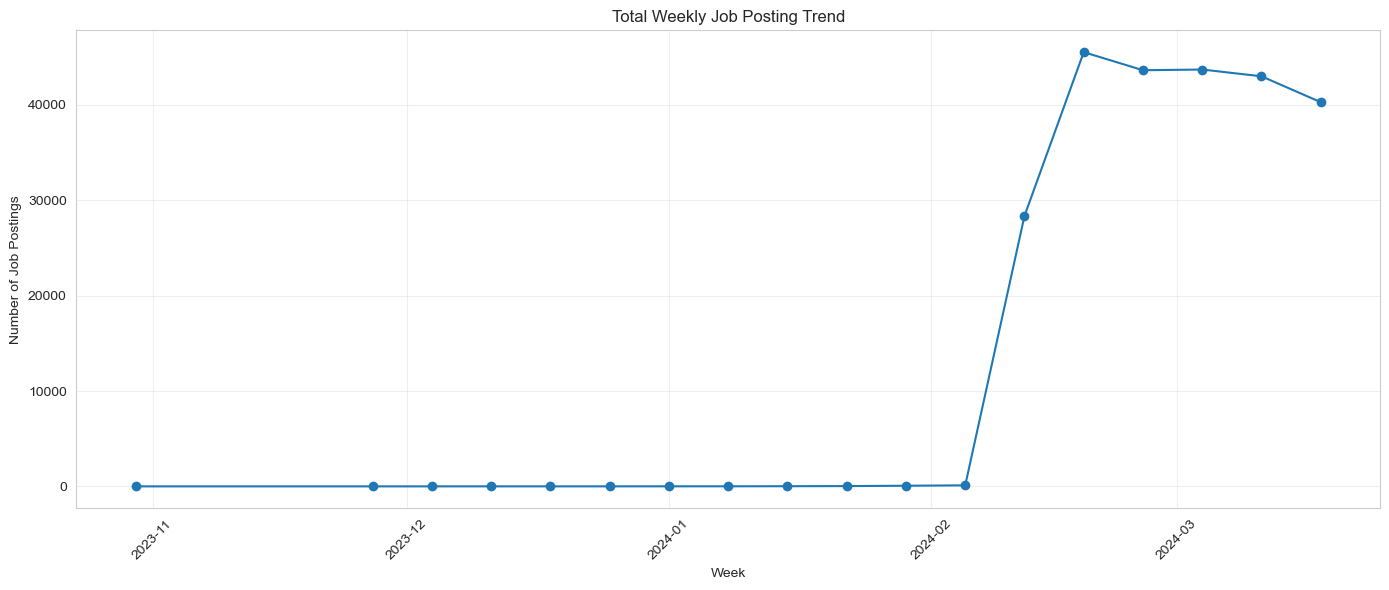

In [188]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_summary['week'],
    weekly_summary['total_jobs'],
    marker='o'
)

plt.title('Total Weekly Job Posting Trend')
plt.xlabel('Week')
plt.ylabel('Number of Job Postings')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [189]:
# Identify the highest-demand categories

category_totals = (
    weekly_pivot
    .drop(columns=['Other'], errors='ignore')
    .sum()
    .sort_values(ascending=False)
)

top_categories = category_totals.head(10)

display(
    top_categories.reset_index(
        name='total_postings'
    ).rename(columns={'index': 'job_category'})
)

,job_category,total_postings
0,Digital Marketing & SEO,16004
1,Software & Web Development,14619
2,"Writing, Translation & Editing",12243
3,E-commerce & Online Marketplace,10930
4,Graphic & UI/UX Design,9401
5,Video & Content Creation,8905
6,Virtual Assistance & Administration,5006
7,Sales & Business Development,4469
8,Data Science & Analytics,3670
9,Customer Support & CRM,1962


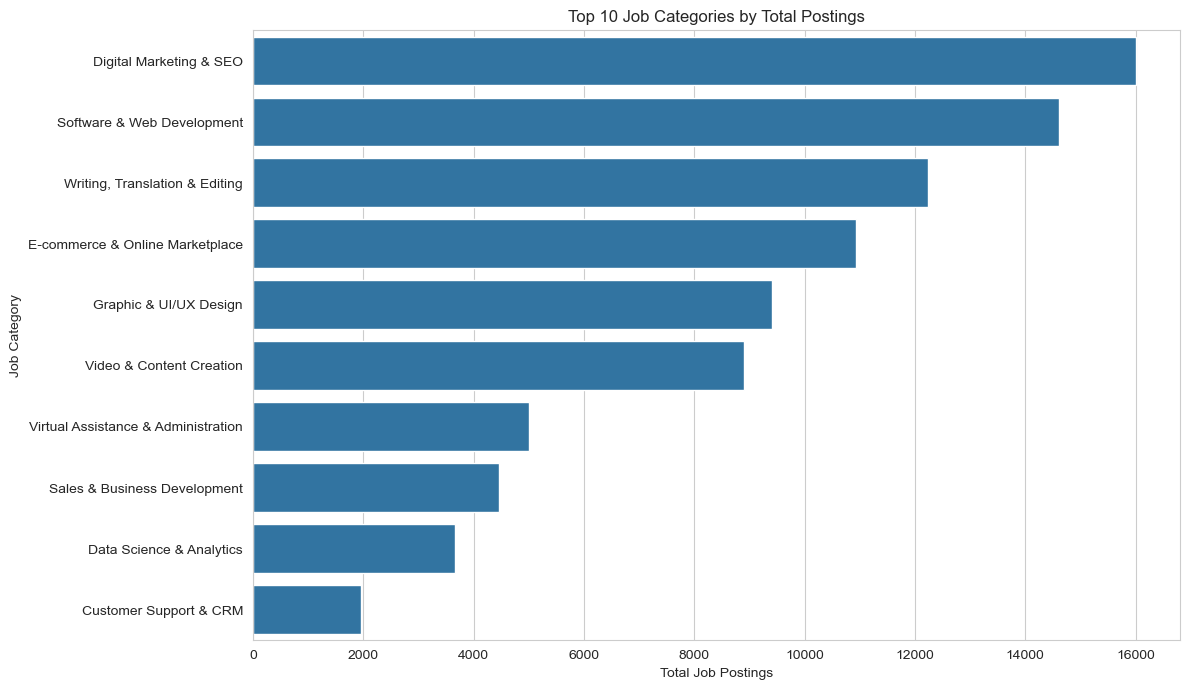

In [190]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title('Top 10 Job Categories by Total Postings')
plt.xlabel('Total Job Postings')
plt.ylabel('Job Category')
plt.tight_layout()
plt.show()

In [191]:
# Prepare the forecasting dataset

# Select the top 10 categories
selected_categories = top_categories.index.tolist()

# Keep data from February 12 onward
model_data = weekly_pivot.loc[
    weekly_pivot.index >= '2024-02-12',
    selected_categories
].copy()

# Chronological train-test split
train_data = model_data.iloc[:-1]
test_data = model_data.iloc[-1:]

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

display(train_data)
display(test_data)

Training shape: (5, 10)
Testing shape: (1, 10)

Training period:
2024-02-12 00:00:00 to 2024-03-11 00:00:00

Testing period:
2024-03-18 00:00:00 to 2024-03-18 00:00:00


job_category,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-02-12,1805,1704,1533,1297,1082,980,665,502,424,238
2024-02-19,2827,2624,2983,1921,1699,1571,1192,742,725,362
2024-02-26,2855,2635,1969,1996,1648,1589,804,796,611,315
2024-03-04,2978,2609,1939,1931,1709,1653,819,767,652,371
2024-03-11,2879,2599,2043,1928,1687,1630,826,846,629,319


job_category,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-03-18,2639,2440,1762,1845,1573,1477,693,807,625,348


In [192]:
# Prepare forecasting features

# Create lag-based forecasting features
X = pd.DataFrame(index=model_data.index)

for category in selected_categories:

    # Previous week's demand
    X[f'{category}_lag_1'] = model_data[category].shift(1)

    # Demand from two weeks earlier
    X[f'{category}_lag_2'] = model_data[category].shift(2)

    # Average demand over the previous three weeks
    X[f'{category}_rolling_mean_3'] = (
        model_data[category]
        .shift(1)
        .rolling(window=3)
        .mean()
    )

# Add a time-based feature
X['week_number'] = np.arange(len(model_data))

# Target: current week's demand for each category
y = model_data[selected_categories].copy()

# Remove rows where lag features are unavailable
valid_indices = X.dropna().index

X = X.loc[valid_indices]
y = y.loc[valid_indices]

# Chronological train-test split
split_index = len(X) - 1

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Feature dataset shape:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

print("\nFeature columns:")
display(X.head())

print("\nTraining target:")
display(y_train)

print("\nTesting target:")
display(y_test)

Feature dataset shape: (3, 31)
Training features: (2, 31)
Testing features: (1, 31)

Training period:
2024-03-04 00:00:00 to 2024-03-11 00:00:00

Testing period:
2024-03-18 00:00:00 to 2024-03-18 00:00:00

Feature columns:


,Digital Marketing & SEO_lag_1,Digital Marketing & SEO_lag_2,Digital Marketing & SEO_rolling_mean_3,Software & Web Development_lag_1,Software & Web Development_lag_2,Software & Web Development_rolling_mean_3,"Writing, Translation & Editing_lag_1","Writing, Translation & Editing_lag_2","Writing, Translation & Editing_rolling_mean_3",E-commerce & Online Marketplace_lag_1,E-commerce & Online Marketplace_lag_2,E-commerce & Online Marketplace_rolling_mean_3,Graphic & UI/UX Design_lag_1,Graphic & UI/UX Design_lag_2,Graphic & UI/UX Design_rolling_mean_3,Video & Content Creation_lag_1,Video & Content Creation_lag_2,Video & Content Creation_rolling_mean_3,Virtual Assistance & Administration_lag_1,Virtual Assistance & Administration_lag_2,Virtual Assistance & Administration_rolling_mean_3,Sales & Business Development_lag_1,Sales & Business Development_lag_2,Sales & Business Development_rolling_mean_3,Data Science & Analytics_lag_1,Data Science & Analytics_lag_2,Data Science & Analytics_rolling_mean_3,Customer Support & CRM_lag_1,Customer Support & CRM_lag_2,Customer Support & CRM_rolling_mean_3,week_number
week,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-03-04,2855.0,2827.0,2495.666667,2635.0,2624.0,2321.000000,1969.0,2983.0,2161.666667,1996.0,1921.0,1738.000000,1648.0,1699.0,1476.333333,1589.0,1571.0,1380.000000,804.0,1192.0,887.000000,796.0,742.0,680.000000,611.0,725.0,586.666667,315.0,362.0,305.000000,3
2024-03-11,2978.0,2855.0,2886.666667,2609.0,2635.0,2622.666667,1939.0,1969.0,2297.000000,1931.0,1996.0,1949.333333,1709.0,1648.0,1685.333333,1653.0,1589.0,1604.333333,819.0,804.0,938.333333,767.0,796.0,768.333333,652.0,611.0,662.666667,371.0,315.0,349.333333,4
2024-03-18,2879.0,2978.0,2904.000000,2599.0,2609.0,2614.333333,2043.0,1939.0,1983.666667,1928.0,1931.0,1951.666667,1687.0,1709.0,1681.333333,1630.0,1653.0,1624.000000,826.0,819.0,816.333333,846.0,767.0,803.000000,629.0,652.0,630.666667,319.0,371.0,335.000000,5



Training target:


job_category,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-03-04,2978,2609,1939,1931,1709,1653,819,767,652,371
2024-03-11,2879,2599,2043,1928,1687,1630,826,846,629,319



Testing target:


job_category,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-03-18,2639,2440,1762,1845,1573,1477,693,807,625,348


In [193]:
# Train a forecasting model

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict job demand for the test week
y_pred = rf_model.predict(X_test)

# Convert predictions into a DataFrame
prediction_df = pd.DataFrame(
    y_pred,
    columns=selected_categories,
    index=y_test.index
)

# Display actual vs predicted demand
print("Actual Job Demand:")
display(y_test)

print("Predicted Job Demand:")
display(prediction_df.round(0))

print("Model training completed successfully!")

Actual Job Demand:


job_category,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-03-18,2639,2440,1762,1845,1573,1477,693,807,625,348


Predicted Job Demand:


,Digital Marketing & SEO,Software & Web Development,"Writing, Translation & Editing",E-commerce & Online Marketplace,Graphic & UI/UX Design,Video & Content Creation,Virtual Assistance & Administration,Sales & Business Development,Data Science & Analytics,Customer Support & CRM
week,,,,,,,,,,
2024-03-18,2925.0,2604.0,1995.0,1929.0,1697.0,1641.0,823.0,810.0,640.0,343.0


Model training completed successfully!


In [194]:
# Evaluate model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics for each category
results = []

for category in selected_categories:

    actual = y_test[category].values
    predicted = prediction_df[category].values

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    results.append({
        'Job Category': category,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

# Create evaluation table
evaluation_df = pd.DataFrame(results)

display(evaluation_df.round(2))

# Calculate overall metrics
overall_mae = mean_absolute_error(
    y_test.values.flatten(),
    prediction_df.values.flatten()
)

overall_rmse = np.sqrt(
    mean_squared_error(
        y_test.values.flatten(),
        prediction_df.values.flatten()
    )
)

print("Overall Model Performance")
print("-------------------------")
print("MAE:", round(overall_mae, 2))
print("RMSE:", round(overall_rmse, 2))
print("R2 Score:", round(
    r2_score(
        y_test.values.flatten(),
        prediction_df.values.flatten()
    ), 4
))

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning:

R^2 score is not well-defined with less than two samples.

C:\Users\Admin\a

,Job Category,MAE,RMSE,R2 Score
0,Digital Marketing & SEO,285.54,285.54,NaN
1,Software & Web Development,163.60,163.60,NaN
2,"Writing, Translation & Editing",233.16,233.16,NaN
3,E-commerce & Online Marketplace,84.38,84.38,NaN
4,Graphic & UI/UX Design,124.12,124.12,NaN
5,Video & Content Creation,163.58,163.58,NaN
6,Virtual Assistance & Administration,129.78,129.78,NaN
7,Sales & Business Development,2.66,2.66,NaN
8,Data Science & Analytics,14.58,14.58,NaN
9,Customer Support & CRM,5.08,5.08,NaN


Overall Model Performance
-------------------------
MAE: 120.65
RMSE: 151.34
R2 Score: 0.9586


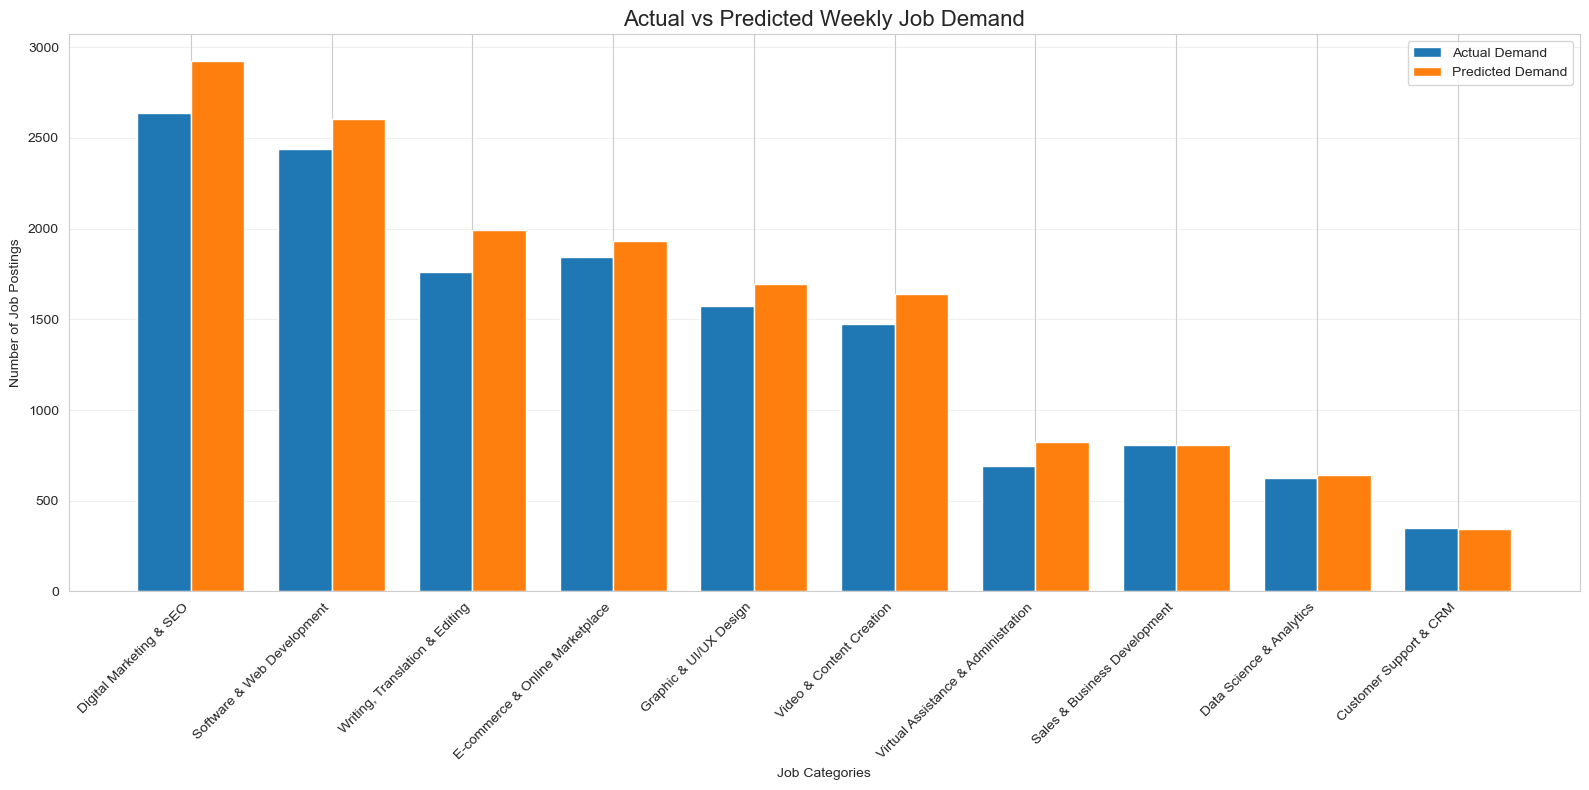

In [195]:
# Visualize actual vs predicted job demand

# Prepare chart values
categories = selected_categories
actual_values = y_test.iloc[0].values
predicted_values = prediction_df.iloc[0].values

x = np.arange(len(categories))
width = 0.38

# Create grouped bar chart
plt.figure(figsize=(16, 8))

plt.bar(
    x - width / 2,
    actual_values,
    width,
    label='Actual Demand'
)

plt.bar(
    x + width / 2,
    predicted_values,
    width,
    label='Predicted Demand'
)

plt.title(
    'Actual vs Predicted Weekly Job Demand',
    fontsize=16
)

plt.xlabel('Job Categories')
plt.ylabel('Number of Job Postings')

plt.xticks(
    x,
    categories,
    rotation=45,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Conclusion – Predicting High-Demand Job Roles

In this task, historical weekly job posting patterns were analyzed to identify and predict high-demand job categories. The top 10 job categories were selected based on their total posting frequency, and a Random Forest Regressor was developed using lag-based features, including previous week's demand, demand from two weeks earlier, and a three-week rolling average.

The model predicted that **Digital Marketing & SEO** would have the highest demand, with approximately 2,925 postings, followed by **Software & Web Development** with 2,604 postings. Other categories showing considerable demand included Writing, Translation & Editing (1,995), E-commerce & Online Marketplace (1,929), and Graphic & UI/UX Design (1,697).

The model evaluation produced an overall Mean Absolute Error (MAE) of 120.65 and Root Mean Squared Error (RMSE) of 151.34. The calculated R² score was 0.9586; however, this result should be interpreted cautiously because the test set contained only one weekly observation. Therefore, it does not establish reliable forecasting accuracy.

The actual-versus-predicted visualization helped compare the model's estimates with real posting counts and identify categories where demand was overestimated or underestimated.

Overall, the analysis indicates that Digital Marketing, Software Development, E-commerce, and Content Creation were among the highest-demand categories in the dataset. However, the limited historical period and small training dataset restrict the reliability of future predictions. More historical weekly data would be required to develop and validate a dependable forecasting model.



# Task 4 – Compare Average Hourly Rates Across Countries.

In [196]:
# Prepare the country-wise hourly rate dataset

# Create a copy of the original dataset
country_df = df.copy()

# Convert hourly rate columns into numeric values
country_df['hourly_low'] = pd.to_numeric(
    country_df['hourly_low'],
    errors='coerce'
)

country_df['hourly_high'] = pd.to_numeric(
    country_df['hourly_high'],
    errors='coerce'
)

# Keep only hourly jobs
country_df = country_df[
    country_df['is_hourly'] == True
].copy()

# Remove records with missing country or hourly rates
country_df = country_df.dropna(
    subset=['country', 'hourly_low', 'hourly_high']
)

# Calculate average hourly rate (midpoint)
country_df['hourly_midpoint'] = (
    country_df['hourly_low'] +
    country_df['hourly_high']
) / 2

# Remove invalid or non-positive hourly rates
country_df = country_df[
    country_df['hourly_midpoint'] > 0
].copy()

# Display dataset information
print("Cleaned hourly dataset shape:", country_df.shape)

print("\nNumber of unique countries:")
print(country_df['country'].nunique())

print("\nMissing values:")
print(country_df[['country', 'hourly_midpoint']].isnull().sum())

print("\nSample records:")
display(
    country_df[
        ['country', 'hourly_low', 'hourly_high', 'hourly_midpoint']
    ].head(10)
)

Cleaned hourly dataset shape: (96825, 9)

Number of unique countries:
191

Missing values:
country            0
hourly_midpoint    0
dtype: int64

Sample records:


,country,hourly_low,hourly_high,hourly_midpoint
2,United States,10.0,30.0,20.0
7,India,7.0,22.0,14.5
13,United Kingdom,40.0,75.0,57.5
15,Malaysia,30.0,50.0,40.0
18,India,12.0,30.0,21.0
19,Canada,4.0,8.0,6.0
21,Saudi Arabia,15.0,30.0,22.5
24,United States,15.0,50.0,32.5
27,United States,6.0,15.0,10.5
29,United States,5.0,15.0,10.0


In [197]:
# Calculate average hourly rates by country

# Clean country names
country_df['country'] = country_df['country'].str.strip()

# Calculate country-wise statistics
country_salary = (
    country_df
    .groupby('country')
    .agg(
        average_hourly_rate=('hourly_midpoint', 'mean'),
        median_hourly_rate=('hourly_midpoint', 'median'),
        total_jobs=('hourly_midpoint', 'count')
    )
    .reset_index()
)

# Sort countries by average hourly rate
country_salary = country_salary.sort_values(
    by='average_hourly_rate',
    ascending=False
)

# Filter countries with at least 30 job postings
reliable_countries = country_salary[
    country_salary['total_jobs'] >= 30
].copy()

print("Total countries:", len(country_salary))

print(
    "Countries with at least 30 postings:",
    len(reliable_countries)
)

# Display top 15 countries
print("\nTop 15 Countries by Average Hourly Rate")

display(
    reliable_countries
    .head(15)
    .round(2)
)

# Display bottom 15 countries
print("\nBottom 15 Countries by Average Hourly Rate")

display(
    reliable_countries
    .sort_values('average_hourly_rate')
    .head(15)
    .round(2)
)

Total countries: 191
Countries with at least 30 postings: 91

Top 15 Countries by Average Hourly Rate


,country,average_hourly_rate,median_hourly_rate,total_jobs
105,Malaysia,48.10,22.5,325
169,Thailand,42.21,22.5,287
89,Jordan,36.15,22.5,55
180,United States,32.58,25.0,46620
96,Latvia,32.39,30.0,106
78,Hungary,32.32,25.0,148
44,Cyprus,31.89,25.0,160
91,Kenya,31.82,26.0,314
14,Bangladesh,31.32,20.0,733
37,Colombia,31.26,22.5,239



Bottom 15 Countries by Average Hourly Rate


,country,average_hourly_rate,median_hourly_rate,total_jobs
161,South Korea,15.44,10.00,270
167,Taiwan,15.96,15.00,53
163,Sri Lanka,19.45,17.50,60
42,Croatia,19.47,16.50,78
186,Venezuela,19.67,20.00,63
49,Dominican Republic,19.86,15.25,54
184,Uzbekistan,21.41,18.50,41
158,Slovenia,21.99,14.50,113
87,Japan,21.99,15.00,246
1,Algeria,22.04,22.50,37


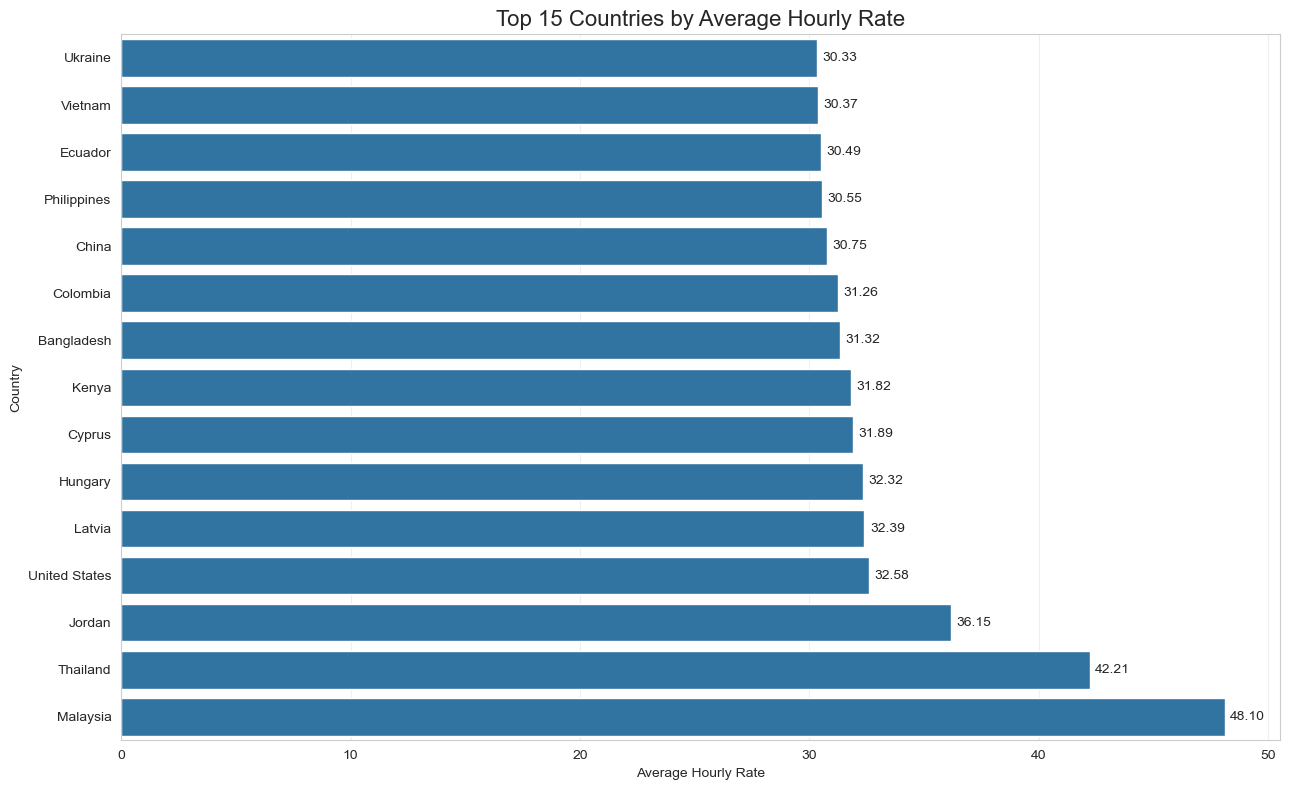

In [198]:
# Visualize average hourly rates by country

# Select top 15 countries
top_15_countries = (
    reliable_countries
    .nlargest(15, 'average_hourly_rate')
    .sort_values('average_hourly_rate', ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=top_15_countries,
    x='average_hourly_rate',
    y='country'
)

# Add average rate labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=4
    )

plt.title(
    'Top 15 Countries by Average Hourly Rate',
    fontsize=16
)

plt.xlabel('Average Hourly Rate')
plt.ylabel('Country')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

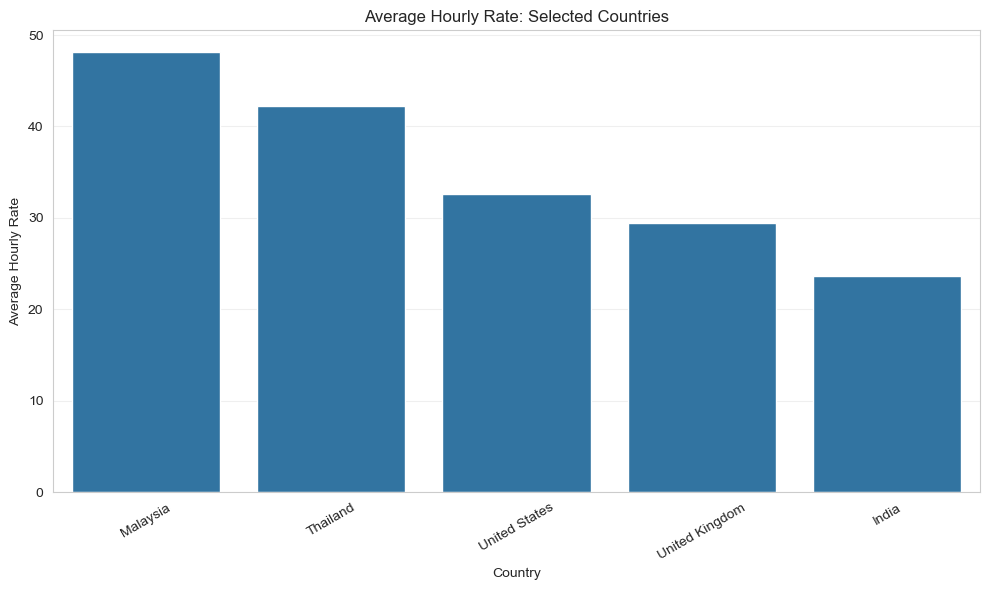

,country,average_hourly_rate,median_hourly_rate,total_jobs
105,Malaysia,48.10,22.5,325
169,Thailand,42.21,22.5,287
180,United States,32.58,25.0,46620
179,United Kingdom,29.49,22.5,8113
80,India,23.68,20.0,4337


In [199]:
# Compare selected countries

selected_countries = [
    'India',
    'United States',
    'Malaysia',
    'Thailand',
    'United Kingdom'
]

comparison_df = reliable_countries[
    reliable_countries['country'].isin(selected_countries)
].sort_values('average_hourly_rate', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x='country',
    y='average_hourly_rate'
)

plt.title('Average Hourly Rate: Selected Countries')
plt.xlabel('Country')
plt.ylabel('Average Hourly Rate')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

display(comparison_df.round(2))

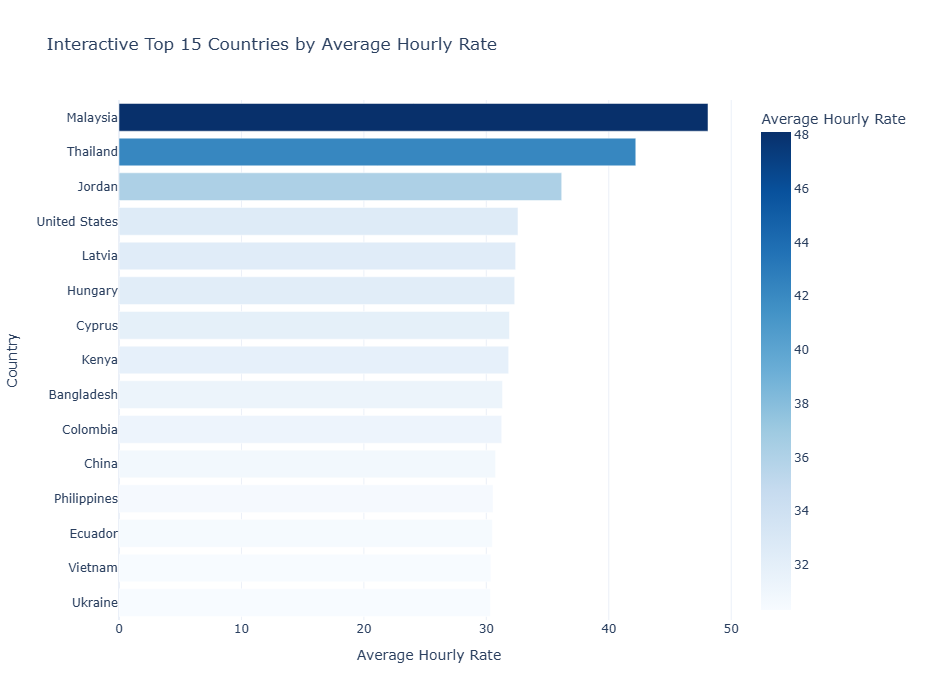

In [200]:
# Create an interactive country comparison chart

import plotly.express as px

# Select top 15 countries
interactive_data = (
    reliable_countries
    .nlargest(15, 'average_hourly_rate')
    .sort_values('average_hourly_rate', ascending=True)
)

# Create interactive chart
fig = px.bar(
    interactive_data,
    x='average_hourly_rate',
    y='country',
    orientation='h',
    color='average_hourly_rate',
    hover_data={
        'average_hourly_rate': ':.2f',
        'median_hourly_rate': ':.2f',
        'total_jobs': True
    },
    title='Interactive Top 15 Countries by Average Hourly Rate',
    labels={
        'average_hourly_rate': 'Average Hourly Rate',
        'country': 'Country'
    },
    color_continuous_scale='Blues'
)

fig.update_layout(
    height=700,
    xaxis_title='Average Hourly Rate',
    yaxis_title='Country',
    template='plotly_white'
)

fig.show()

# Conclusion – Comparison of Average Hourly Rates Across Countries

In this task, hourly job postings were analyzed to compare average hourly rates across different geographical locations. The analysis used a cleaned dataset containing **96,825 hourly job postings from 191 countries**.

To ensure a more meaningful comparison, countries with fewer than 30 job postings were excluded, leaving 91 countries for the analysis.

The results showed that **Malaysia** had the highest average hourly rate of 48.10, followed by **Thailand** at 42.21 and **Jordan** at 36.15. The United States recorded an average hourly rate of 32.58 across 46,620 postings, while the United Kingdom recorded 29.49 across 8,113 postings. India had an average hourly rate of 23.68 based on 4,337 postings.

At the lower end, South Korea recorded the lowest average hourly rate among the selected countries, at 15.44, followed by Taiwan at 15.96.

The comparison between average and median rates also revealed differences in salary distributions. For example, Malaysia and Thailand had average rates of 48.10 and 42.21, respectively, while their median rates were both 22.50. This suggests that relatively high-rate postings may be influencing their averages.

Horizontal bar charts were created to compare the highest-paying countries, and an interactive Plotly chart was developed to display average rates, median rates, and job posting counts through hover information.

Overall, the analysis highlights geographical differences in the hourly rates offered for freelance jobs. However, these results should be interpreted carefully because the dataset does not establish the currency, and hourly rates may also depend on job category, experience, project complexity, and client requirements. Countries with smaller posting counts may have less representative averages.

Therefore, the analysis provides a useful overview of geographical differences in advertised hourly rates rather than a definitive comparison of actual earnings across countries.

In [201]:
# Use for dataset for task 5 

# Check whether job_category is available
print(trend_df.columns.tolist())

# Check category distribution
display(
    trend_df['job_category'].value_counts().head(20)
)

# Export categorized job-level dataset
trend_df.to_csv(
    'data/job_postings_with_categories.csv',
    index=False
)

print("Categorized dataset exported successfully!")

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'year', 'month', 'year_month', 'month_name', 'job_category']


job_category
Other                                   150932
Digital Marketing & SEO                  16004
Software & Web Development               14619
Writing, Translation & Editing           12243
E-commerce & Online Marketplace          10930
Graphic & UI/UX Design                    9401
Video & Content Creation                  8905
Virtual Assistance & Administration       5006
Sales & Business Development              4469
Data Science & Analytics                  3670
Customer Support & CRM                    1962
Finance, Accounting & Tax                 1937
Artificial Intelligence & Automation      1588
Project & Product Management               969
HR & Recruitment                           917
Education & Research                       514
Cybersecurity & IT Infrastructure          442
Legal & Documentation Services             320
Name: count, dtype: int64

Categorized dataset exported successfully!
